*Text under CC-BY 4.0, code under BSD-3-Clause. (c) 2026 Francesco Mario Antonio Mitrotta.*

# A Polynomial Chaos Surrogate of the Open-Hole Tension Plate

[NB9](09_training_campaign_open_hole_tension.ipynb) ran 12,340 Abaqus analyses of the open-hole tension (OHT) plate of [NB6](06_open_hole_tension.ipynb), mesh M1, with 15 uncertain ply properties, and checked them: 12,197 of the 12,240 training runs and all 100 validation runs can be used. This notebook first reads them as the Monte Carlo campaign they are, then fits the **polynomial chaos expansion** (PCE) of [NB8](08_polynomial_chaos_expansion.ipynb) to them, at orders 1 to 3, for the two loads of a strength assessment, and uses the best surrogate for what it was built for: the mean, the standard deviation, the 5th percentile and the probability density of each load, and their Sobol' indices. Every result is set beside the raw Abaqus runs and beside [Thapa et al. (2021)](https://doi.org/10.1007/s00158-020-02690-5), whose study of the same plate this series follows.

## Learning goal

By the end of this notebook you will be able to:

- estimate the mean, standard deviation, 5th percentile and distribution of the two loads directly from the raw Abaqus
  runs, check that the estimates have converged, and decide whether keeping the runs with much viscous energy matters;
- fit PCE surrogates of orders 1 to 3 to an Abaqus campaign, and judge from the validation and in-sample errors how
  their accuracy depends on the order and on the number of training runs, reading the error as the share of a load's
  variance that the surrogate explains and the share it leaves unexplained;
- propagate the input uncertainty through the best surrogate (mean, standard deviation, 5th percentile,
  probability density), check the result against the raw runs of Part 2, and say which statistics the unexplained
  variance changes and which it leaves alone;
- read the Sobol' indices of the plate's two loads from the surrogate's coefficients, interpret them as shares of the
  explained variance, and say what the unexplained part could add;
- compare the surrogate, its statistics and its indices with those of Thapa et al. (2021), and say what the
  differences point to.


First, the imports. The PCE functions are NB8's own, imported unchanged from `scripts/pce.py`:
`total_order_indices` (the multi-indices $\boldsymbol\alpha$), `design_matrix` ($\Psi$), `fit_pce` (the least-squares
fit), `relative_mse` ($\varepsilon$), `basis_norms` ($\mathrm E[\psi^2]$) and `sobol_indices` (NB8, Part 2, Step 6). From
`scripts/oht_campaign.py`, NB9's campaign driver, come `drop_failed_frame` and `acceptance_reason`, so that this
notebook reads and screens the runs exactly as NB9 did. SciPy's `gaussian_kde` is the kernel density estimate of NB2, and `bootstrap_ci` (from `scripts/bootstrap.py`) is NB3's
percentile-bootstrap interval for any statistic.

In [1]:
# Standard library: reading the design files (CSV) and the results (JSON), and file paths.
import csv
import json
import math
import sys
from pathlib import Path

# NumPy for the arrays, Matplotlib for the figures, SciPy's kernel density estimate (NB2).
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

# NB8's PCE functions, unchanged, and NB9's reading and screening of a run.
sys.path.insert(0, "../scripts")
from pce import basis_norms, design_matrix, fit_pce, relative_mse, sobol_indices, total_order_indices
from bootstrap import bootstrap_ci
from oht_campaign import acceptance_reason, drop_failed_frame

## Part 1 &ndash; The runs

NB9 saved each run as a JSON file in `runs/nb09/train/` and `runs/nb09/validation/`, and the inputs of each run in the
design files `design_train.csv` and `design_validation.csv`, in physical units. The surrogate works in the standardised
inputs $\xi_i$ of NB8, so the cell turns each design row back into them, $\xi_i=(x_i/\mu_i-1)/\mathrm{CoV}_i$, with
NB9's means and $\mathrm{CoV}_i=0.1$. It then reads every result, removes the failed last frame of a job that stopped
early, applies NB9's screening rule, and keeps, for every accepted run, the two outputs and the viscous-to-damage
energy ratio at the peak, ALLCD/ALLDMD, which Parts 2 and 3 need. The outputs are the loads at first-ply failure,
$P_{FPF}$, and at the peak, $P_{ULT}$ (NB9, Part 1). Reading the 12,340 files takes a few minutes.

In [2]:
# The 15 uncertain inputs in design-file order, their means mu_i (NB6, NB9) and their CoV; the number of inputs d.
INPUT_NAMES = ["E1", "E2", "nu12", "G12", "G23", "X_T", "X_C", "Y_T", "Y_C", "S_L", "S_T",
               "G_fT", "G_fC", "G_mT", "G_mC"]
INPUT_MEANS = np.array([172400.0, 10300.0, 0.32, 5520.0, 3450.0, 2826.5, 1620.0, 65.5, 248.0, 122.0, 122.0,
                        81.5, 106.3, 0.2774, 0.7879])
COV_INPUT = 0.1
# The number of inputs, d = 15.
D = len(INPUT_NAMES)
# NB9's campaign folder, and the two outputs: plain name -> plot label.
RUNS = Path("../runs/nb09")
# (The outputs are read from each file as fpf.rf2_n and f_peak_n.)
OUTPUTS = {"P_FPF": r"$P_{FPF}$", "P_ULT": r"$P_{ULT}$"}


def load_campaign(design_csv, folder):
    """Standardised inputs, screening verdict, outputs and energy ratio of every run of a campaign.

    Parameters
    ----------
    design_csv : Path
        Design file: a header line, then one row of 15 physical inputs per run.
    folder : Path
        Folder of the result files sNNNN.json, one per design row.

    Returns
    -------
    xi : (n, d) array
        Standardised inputs [-].
    ok : (n,) bool array
        True if NB9's rule accepts the run.
    y : (n, 2) array
        P_FPF and P_ULT [N]; NaN for a rejected run.
    ratio : (n,) array
        ALLCD/ALLDMD at the peak [-]; NaN for a rejected run.
    """
    # The physical inputs, and the standardised ones from the transform x = mu (1 + CoV xi).
    with open(design_csv, newline="") as f:
        x = np.array([[float(v) for v in row] for row in list(csv.reader(f))[1:]])
    xi = (x / INPUT_MEANS - 1.0) / COV_INPUT
    # Verdicts, outputs and energy ratios, filled run by run (NaN stays for a rejected run).
    ok, y, ratio = np.zeros(len(x), bool), np.full((len(x), 2), np.nan), np.full(len(x), np.nan)
    # One result file per design row.
    for i in range(len(x)):
        # Read the run, drop a failed last frame, and screen it as NB9 does.
        with open(folder / ("s%04d.json" % i)) as f:
            r = drop_failed_frame(json.load(f))
        ok[i] = acceptance_reason(r) == ""
        if ok[i]:
            # The two loads [N], and the energy ratio at the frame of the peak.
            k = r["peak_index"]
            y[i] = r["fpf"]["rf2_n"], r["f_peak_n"]
            ratio[i] = r["allcd"][k] / r["alldmd"][k]
    # Everything the rest of the notebook needs from the campaign.
    return xi, ok, y, ratio


# Both campaigns: training (12,240 rows) and validation (100 rows).
xi_train, ok_train, Y_train, ratio_train = load_campaign(RUNS / "design_train.csv", RUNS / "train")
xi_valid, ok_valid, Y_valid, ratio_valid = load_campaign(RUNS / "design_validation.csv", RUNS / "validation")
# NB9 accepted every validation run; stop here if that has changed.
assert ok_valid.all(), "every validation run is expected to be accepted (NB9, Part 4)"
# How many runs each campaign has, and how many are accepted.
print("training runs: %d, accepted %d; validation runs: %d, accepted %d"
      % (len(ok_train), ok_train.sum(), len(ok_valid), ok_valid.sum()))

training runs: 12240, accepted 12197; validation runs: 100, accepted 100


All 12,197 training runs and 100 validation runs that NB9 accepted are back, with the same verdicts: reading the
files through the driver's own functions reproduces NB9's screening exactly. From here on, "the runs" means these
12,297 accepted runs.

## Part 2 &ndash; The direct Monte Carlo of the raw runs

The campaign gives us a Monte Carlo estimate before any surrogate is fitted. NB9's training design is a plain random sample of
the inputs, so the accepted training runs and the validation runs together are a Monte Carlo campaign (NB2) of 12,297 Abaqus
runs, and its statistics are the **raw** estimates. (The 43 rejected runs are missing; they are 0.35% of the design, and NB9,
Part 4, Step 3 showed that they leave no hole in it.) This part asks three things in turn: has this Monte Carlo converged,
with the bootstrap of [NB3](03_convergence_nlgeom_off_vs_on.ipynb) (Step 1); what are the statistics and the distribution of
the two loads (Step 2); and does keeping the 233 runs with `ALLCD/ALLDMD` of 1% or more change them, and can they stay (Step 3)? These raw values are the
reference that the surrogates of Parts 3 and 4 are judged against.

### Step 1 &ndash; Has the raw Monte Carlo converged?

NB3 stops a campaign when the bootstrap 95% interval of its estimate is narrow enough. The 12,297 runs exist already, so the question here is the reverse: how do the estimates and their intervals change as more of them are used? The runs are in the order of NB9's training stream, then the 100 validation runs: independent random inputs in random order, so the first $n$ runs are themselves a campaign of $n$ runs. For 25 values of $n$ from 100 to 12,297 on a logarithmic axis, the cell computes for each load

- the mean, and
- the 5th percentile $Q_{5\%}$ as NB2's order statistic: the sample sorted and read at 5% (`np.percentile`),

each with a 95% bootstrap interval from NB3's `bootstrap_ci` (1,000 resamples of the $n$ runs with replacement, seed 102). It draws them against $n$, and prints the final values and the first $n$ at which the relative half-width of each interval is within NB3's target of 1%. The curves are one realisation of a campaign: another random order of the same runs would wander differently within the bands.

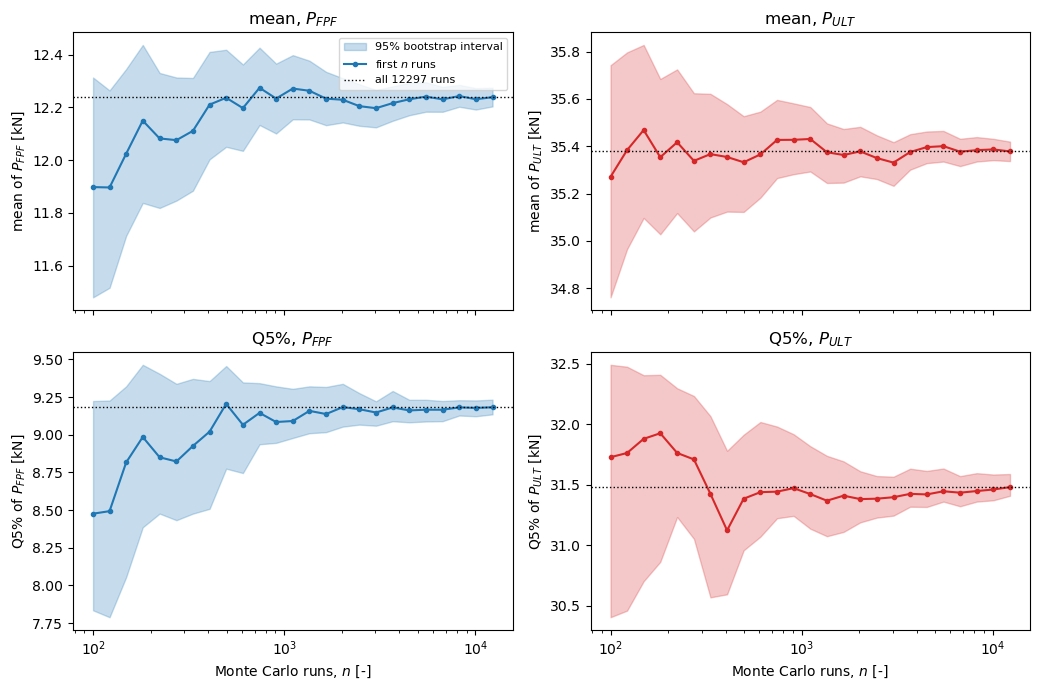

load   stat    estimate      95% interval [kN]  half-width first n within 1%
P_FPF  mean   12.238 kN   [ 12.203,  12.275]        0.29%   1109
P_FPF  Q5%     9.183 kN   [  9.136,   9.233]        0.53%   3022
P_ULT  mean   35.378 kN   [ 35.337,  35.419]        0.12%   182
P_ULT  Q5%    31.481 kN   [ 31.410,  31.590]        0.29%   1656


In [3]:
# The raw sample: every accepted run, training stream first and then validation [N], and the number of runs.
Y_raw = np.vstack([Y_train[ok_train], Y_valid])
n_raw = len(Y_raw)
# The two estimators of NB3: the mean, and the 5th percentile read off the sorted sample (NB2's order statistic).
mean_fn = lambda a, axis: a.mean(axis=axis)
q5_fn = lambda a, axis: np.percentile(a, 5, axis=axis)
# 25 campaign sizes n, log-spaced from 100 runs to all of them.
sizes_mc = np.unique(np.geomspace(100, n_raw, 25).round().astype(int))
# For each load and statistic, the bootstrap result (estimate, 95% interval, ...) of the first n runs, for every n.
conv = {}
for o, name in enumerate(OUTPUTS):
    for stat, fn in (("mean", mean_fn), ("Q5%", q5_fn)):
        # The same seed for every curve (102); the resamples of one n are independent of those of another.
        rng = np.random.default_rng(102)
        conv[name, stat] = [bootstrap_ci(Y_raw[:n, o], fn, n_boot=1000, rng=rng) for n in sizes_mc]

# One panel per statistic (rows) and load (columns): the estimate and its 95% band against n [kN].
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.0), sharex=True)
for row, stat in enumerate(("mean", "Q5%")):
    for col, (name, label) in enumerate(OUTPUTS.items()):
        # The bootstrap results of this panel, and their estimate and interval ends as arrays [kN].
        ax, res = axes[row, col], conv[name, stat]
        est, lo, hi = (np.array([r[k] for r in res]) / 1e3 for k in ("estimate", "ci_low", "ci_high"))
        # The band, the estimate from the first n runs, and the value with all runs (where the curve ends).
        ax.fill_between(sizes_mc, lo, hi, color="C%d" % (3 * col), alpha=0.25, label="95% bootstrap interval")
        ax.plot(sizes_mc, est, "o-", ms=3, color="C%d" % (3 * col), label="first $n$ runs")
        ax.axhline(est[-1], color="k", ls=":", lw=1, label="all %d runs" % n_raw)
        # Log axis for n, and the labels.
        ax.set(xscale="log", title="%s, %s" % (stat, label), ylabel="%s of %s [kN]" % (stat, label))
# The shared x label under the lower row, one legend, and the layout.
for ax in axes[1]:
    ax.set_xlabel("Monte Carlo runs, $n$ [-]")
axes[0, 0].legend(fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()
# The final estimates, their intervals, and the first n whose relative half-width is within the 1% target of NB3.
print("%-6s %-5s %10s %22s %11s %s" % ("load", "stat", "estimate", "95% interval [kN]", "half-width", "first n within 1%"))
for (name, stat), res in conv.items():
    # The estimate with all runs, and the first campaign size that met the target (None if none did).
    r = res[-1]
    n_ok = next((n for n, x in zip(sizes_mc, res) if x["rel_half_width"] <= 0.01), None)
    print("%-6s %-5s %7.3f kN   [%7.3f, %7.3f]   %9.2f%%   %s" % (name, stat, r["estimate"] / 1e3, r["ci_low"] / 1e3,
          r["ci_high"] / 1e3, 100 * r["rel_half_width"], n_ok))


**The mean converges first, then the 5th percentile.** For $P_{ULT}$ the bootstrap interval of the mean is within 1% of the mean from $n=182$ runs; for $P_{FPF}$, from $n=1{,}109$. The load with the larger spread needs more runs, in about the ratio of the squared coefficients of variation: $(16.6/6.6)^2=6.3$, against $1{,}109/182=6.1$ ([NB4](04_two_uncertain_inputs.ipynb): $N\propto\mathrm{CoV}^2$). The 5th percentile needs more than the mean, 1,656 runs for $P_{ULT}$ and 3,022 for $P_{FPF}$, as in NB2: the error of a percentile also depends on how few runs fall in the tail. Before about 1,000 runs the curves still wander by more than their final bands: the 5th percentile of $P_{ULT}$, for instance, sits more than half a kilonewton above its final value somewhere between 100 and 250 runs.

With all 12,297 runs both estimators have converged by NB3's standard. The means are $12.238$ kN (95% interval 12.203&ndash;12.275) for $P_{FPF}$ and $35.378$ kN (35.337&ndash;35.419) for $P_{ULT}$; the 5th percentiles are $9.183$ kN (9.136&ndash;9.233) and $31.481$ kN (31.410&ndash;31.590), with relative half-widths of 0.29%, 0.12%, 0.53% and 0.29%. NB3's rule would have stopped the $P_{ULT}$ campaign at about 1,700 runs and the $P_{FPF}$ one at about 3,000; NB9 ran 12,297 for the surrogate's sake, not the Monte Carlo's. The raw runs are therefore a reference to well within 1%, and only differences larger than these intervals mean anything when the surrogates are set beside them in Part 4.

### Step 2 &ndash; The statistics and the distribution of the two loads

With the sample converged, the cell prints the mean, the standard deviation (with $n-1$ in the denominator, NB2) and the 5th
percentile of each load, each with a 95% bootstrap interval from NB3's `bootstrap_ci` (1,000 resamples of all 12,297 runs, seed
103), and draws each load's histogram and kernel density estimate (NB2) with its mean and 5th percentile marked.

load   mean                     std                      5th percentile          
P_FPF  12.238 [12.203, 12.272]   2.026 [ 1.996,  2.053]   9.183 [ 9.135,  9.233]
P_ULT  35.378 [35.333, 35.422]   2.331 [ 2.300,  2.359]  31.481 [31.401, 31.579]


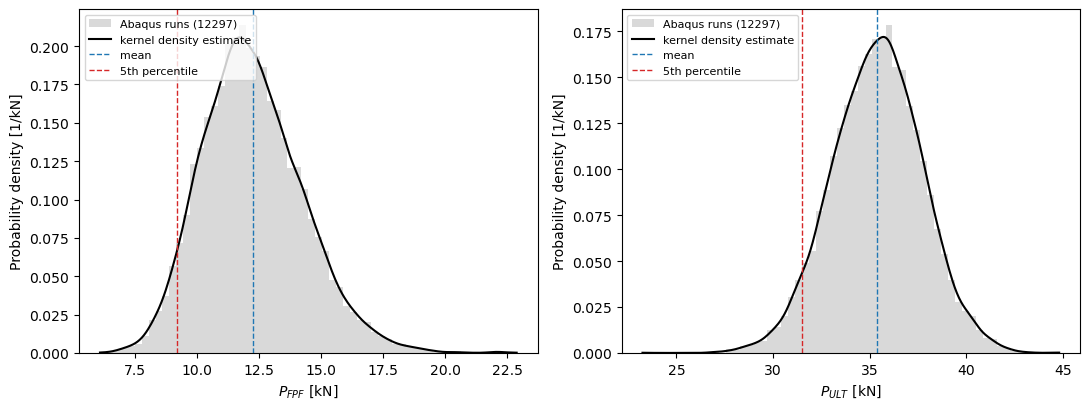

In [4]:
# The three statistics, and the estimator of each: the mean, the standard deviation (n - 1 in the denominator, NB2), Q5%.
STATS = ("mean", "std", "Q5%")
stat_fns = {"mean": mean_fn, "std": lambda a, axis: a.std(axis=axis, ddof=1), "Q5%": q5_fn}
# The raw statistics with their 95% bootstrap intervals, one per load and statistic (seed 103).
raw = {(name, s): bootstrap_ci(Y_raw[:, o], stat_fns[s], rng=np.random.default_rng(103))
       for o, name in enumerate(OUTPUTS) for s in STATS}
# One row per load: each statistic [kN] with its 95% interval.
print("%-6s %-24s %-24s %-24s" % ("load", "mean", "std", "5th percentile"))
for name in OUTPUTS:
    print("%-6s %s" % (name, "  ".join("%6.3f [%6.3f, %6.3f]" % (raw[name, s]["estimate"] / 1e3, raw[name, s]["ci_low"] / 1e3,
                                                                raw[name, s]["ci_high"] / 1e3) for s in STATS)))

# One panel per load: histogram and kernel density estimate [per kN], with the mean and the 5th percentile marked.
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2))
for o, (ax, (name, label)) in enumerate(zip(axes, OUTPUTS.items())):
    # This load's runs [kN], and a grid over their range for the density.
    y = Y_raw[:, o] / 1e3
    grid = np.linspace(y.min(), y.max(), 400)
    # The histogram and its kernel density estimate (NB2).
    ax.hist(y, bins=60, density=True, color="0.85", label="Abaqus runs (%d)" % n_raw)
    ax.plot(grid, gaussian_kde(y)(grid), "k-", lw=1.5, label="kernel density estimate")
    # The mean and the 5th percentile, from the table above.
    ax.axvline(raw[name, "mean"]["estimate"] / 1e3, color="C0", ls="--", lw=1, label="mean")
    ax.axvline(raw[name, "Q5%"]["estimate"] / 1e3, color="C3", ls="--", lw=1, label="5th percentile")
    # Labels and legend.
    ax.set(xlabel="%s [kN]" % label, ylabel="Probability density [1/kN]")
    ax.legend(loc="upper left", fontsize=8)
# Arrange the panels without overlaps.
fig.tight_layout()
plt.show()

For the first-ply load the raw runs give a mean of 12.238 kN and a standard deviation of 2.026 kN; for the peak load, 35.378 kN and
2.331 kN. The 5th percentiles, the values a design allowable looks at, are 9.183 kN and 31.481 kN: 1.51 and 1.67 standard
deviations below the mean. Each statistic is known to within about 0.1 kN or better. (These intervals differ from Step 1's in the third
decimal because they come from a different set of resamples.) The histograms are not symmetric. The first-ply load has a long
upper tail, up to 23 kN, so its mean lies to the right of its peak. The peak load has a long tail on the low side, down to about
23 kN, and those weak runs are the ones that set its 5th percentile.

### Step 3 &ndash; With and without the runs at 1% or more

NB9 flagged the 233 runs whose `ALLCD/ALLDMD` at the peak is 1% or more and could not tell whether viscosity had made their peak
artificially high. Their peak load is part of the raw sample, so this step also decides whether they stay in it: we ask what leaving them out does to the whole distribution of
$P_{ULT}$, not only to its mean. The cell prints the mean, standard deviation and 5th percentile of $P_{ULT}$ with their 95%
bootstrap intervals (seed 103) for all runs, for the runs without the 233, and for the 233 alone, and the share of the 233 below
the 5th percentile and above the 95th percentile of all runs (5% each if they were like the others). It draws the densities of
the 233 and of the others.

all runs             12297 runs: mean 35.378 [35.333, 35.422]  std  2.331 [ 2.300,  2.359]  Q5% 31.481 [31.401, 31.579]


without the flagged  12064 runs: mean 35.382 [35.343, 35.423]  std  2.322 [ 2.290,  2.352]  Q5% 31.506 [31.423, 31.614]
the flagged only       233 runs: mean 35.132 [34.792, 35.492]  std  2.759 [ 2.527,  2.980]  Q5% 30.724 [29.742, 31.212]
share of the flagged runs below the 5th percentile of all runs (31.481 kN): 9.9%; above the 95th (39.137 kN): 4.7%


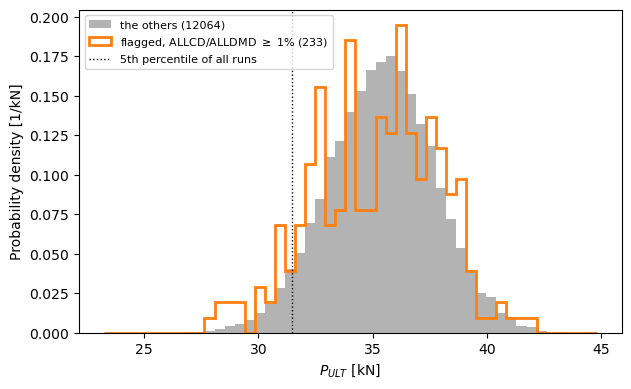

In [5]:
# The flag of each raw run: ALLCD/ALLDMD of 1% or more (the validation runs come after the training runs, as in Y_raw).
flag = np.concatenate([ratio_train[ok_train], ratio_valid]) >= 0.01
# The peak loads of the raw runs [kN].
y_ult = Y_raw[:, 1] / 1e3
# The three groups of runs, and the statistics of each with its 95% bootstrap interval [kN] (seed 103).
groups = {"all runs": np.ones(n_raw, bool), "without the flagged": ~flag, "the flagged only": flag}
for label, sel in groups.items():
    # The three statistics of this group, each with its interval.
    res = [bootstrap_ci(y_ult[sel], stat_fns[s], rng=np.random.default_rng(103)) for s in STATS]
    # One row per group.
    print("%-20s %5d runs: %s" % (label, sel.sum(), "  ".join("%s %6.3f [%6.3f, %6.3f]" % (s, r["estimate"], r["ci_low"], r["ci_high"])
                                                         for s, r in zip(STATS, res))))
# The share of the flagged runs in the lowest 5% and the highest 5% of all runs.
q5, q95 = np.percentile(y_ult, [5, 95])
print("share of the flagged runs below the 5th percentile of all runs (%.3f kN): %.1f%%; above the 95th (%.3f kN): %.1f%%"
      % (q5, 100 * np.mean(y_ult[flag] < q5), q95, 100 * np.mean(y_ult[flag] > q95)))

# The densities of the flagged runs and of the others, with the 5th percentile of all runs [per kN against kN].
fig, ax = plt.subplots(figsize=(7.0, 4.2))
# Common bins for both histograms.
bins = np.linspace(y_ult.min(), y_ult.max(), 50)
# The others as grey bars, the flagged runs as an orange outline, and the 5th percentile of all runs.
ax.hist(y_ult[~flag], bins=bins, density=True, color="0.7", label="the others (%d)" % (~flag).sum())
ax.hist(y_ult[flag], bins=bins, density=True, histtype="step", color="C1", lw=2, label="flagged, ALLCD/ALLDMD $\\geq$ 1%% (%d)" % flag.sum())
ax.axvline(q5, color="k", ls=":", lw=1, label="5th percentile of all runs")
# Labels and legend.
ax.set(xlabel="$P_{ULT}$ [kN]", ylabel="Probability density [1/kN]")
ax.legend(loc="upper left", fontsize=8)
plt.show()

Leaving the 233 runs out hardly changes the distribution of $P_{ULT}$. Without them the mean is 35.382 kN against 35.378 kN,
the standard deviation 2.322 kN against 2.331 kN, and the 5th percentile 31.506 kN against 31.481 kN, a shift of 25 N, about a quarter of the
half-width of that percentile's interval (about 0.1 kN).


The 233 runs alone have a centre a little below the others' (mean 35.132 kN, interval 34.792&ndash;35.492, which contains the others' 35.382 kN) but a wider
spread: a standard deviation of 2.759 kN (2.527&ndash;2.980) against 2.322 kN (2.290&ndash;2.352), which is more than noise. They also
have somewhat more weak runs: 23 of the 233 (9.9%) fall below the 5th percentile of all runs, where 5% would be 12 runs. The orange
histogram is as wide as the grey one or wider, but not shifted to the right, and a peak raised by viscosity would shift it. The
comparison cannot isolate the viscosity, though: the 233 runs have different inputs from the others (NB9: more of them on the
high-$X_T$ side), and different inputs alone could widen the spread. Part 3, Step 2 compares them at the same inputs.


**Decision: they stay.** The 233 runs are 1.9% of the 12,297, so whatever their bias, they can move a statistic of the
sample by only 1.9% of it. For the mean to move by the half-width of its interval, about 45 N, their peaks would have
to be about 2.3 kN (7%) too high on average, and the measured shifts are 5, 9 and 25 N for the mean, standard deviation
and 5th percentile. Nothing in NB9's curves points to a bias that large either. This leaves two questions that the raw
runs cannot answer, because the inputs of the 233 differ from the others': is there a smaller bias, and why is their
spread wider? Part 3, Step 2 asks the surrogate, which compares them at equal inputs.


## Part 3 &ndash; The surrogates of orders 1 to 3, and their error

### Step 1 &ndash; How the error falls with the number of training runs

Now the loop of [Thapa et al. (2021, Fig. 2)](https://doi.org/10.1007/s00158-020-02690-5): for each order $p$, fit
the coefficients by least squares (`fit_pce`, NB8) on accepted training runs, predict the 100 validation runs and
measure the error with NB8's relative mean-square error $\varepsilon$ (Thapa et al., Eq. 34): the share of the output's
variance that the surrogate fails to capture, 0 for a perfect surrogate and about 1 for one no better than the mean.

Computed on the training runs themselves, the same ratio is the **in-sample** $\varepsilon$. A fit that is much
better on the runs it was fitted to than on new runs has learnt features of its own training runs that do not carry
over to new inputs.


**Explained and unexplained variance.** $\varepsilon$ has a second reading that the rest of this notebook uses. A
model run is deterministic, so all the variance of a load comes from the 15 inputs, but the surrogate can follow only
the part of it that a polynomial of its order represents. Call that part the **explained variance**, a share
$1-\varepsilon$ of the load's variance, and the rest, a share $\varepsilon$, the **unexplained variance**. It is not
randomness: running a plate again gives the same load. It is the variation that no polynomial of this order follows
(NB8's truncation loss, plus the cost of estimating the coefficients from finitely many runs), and the surrogate sees it
only as scatter around its trend. For a least-squares fit the two shares add up exactly to the variance of the runs, as
Part 4 checks on the plate. Everything read from the surrogate later, the standard deviation, the percentiles, the
density and the Sobol' indices, describes the explained part only. The mean is the exception, because the constant
term is fitted to the mean of the runs.


How does $\varepsilon$ change with the number of training runs $n_s$? For each order we fit on the **first** $n_s$
accepted runs of the training stream, so that every smaller design is the start of every larger one, as in NB9 (a
rejected row is skipped, so $n_s$ counts accepted runs). We take 16 values of $n_s$ per order, evenly spaced on a
logarithmic axis from $n_s=P+1$ ($n_p=1$, as many runs as coefficients) to all accepted runs, and add $n_p=2$, the
common ratio. With all accepted runs, order 3 has about 15 runs per coefficient, order 2 about 90 and order 1 about 760.

The next cell defines `fit_and_score`, which fits one order on a given set of training rows and returns, for each
output, the coefficients and the validation and in-sample $\varepsilon$.

In [6]:
def fit_and_score(rows, p):
    """Fit order p on the training runs `rows` (accepted ones only).

    Parameters
    ----------
    rows : array of int
        Row numbers of the training runs to fit on.
    p : int
        Total order of the expansion.

    Returns
    -------
    dict
        Output name -> (coefficients, epsilon on the validation runs, epsilon in-sample).
    """
    # The multi-indices of order p, the design matrix at the validation inputs, and a dictionary for the results.
    alphas = total_order_indices(D, p)
    psi_valid = design_matrix(xi_valid, alphas)
    scores = {}
    for o, name in enumerate(OUTPUTS):
        # Least-squares coefficients, then epsilon on the validation runs and on the training runs themselves.
        a = fit_pce(xi_train[rows], Y_train[rows, o], alphas)
        eps_val = relative_mse(Y_valid[:, o], psi_valid @ a)
        eps_in = relative_mse(Y_train[rows, o], design_matrix(xi_train[rows], alphas) @ a)
        # Keep the three for this output.
        scores[name] = (a, eps_val, eps_in)
    return scores

The next cell runs the fits and draws one panel per output. In each panel every order has its colour (darkest for order 1, lightest for order 3): a solid line for
the validation $\varepsilon$ and a dashed line for the in-sample $\varepsilon$ (left out at $n_p=1$, where the fit
passes through every training run and the in-sample error is zero). Both axes are logarithmic, and the dotted line
$\varepsilon=1$ marks a surrogate no better than the mean.

The cell also prints $\varepsilon$ at $n_p=1$, at $n_p=2$ and with all accepted runs, and for the last a 95%
bootstrap interval of the validation $\varepsilon$ (NB3): the 100 validation runs are resampled with replacement
2,000 times (seed 101) and $\varepsilon$ is recomputed for each resample. NB8 showed that $\varepsilon$ from 100 runs
is itself an estimate; the interval says how wide. Last, it prints the peak load's error for orders 2 and 3 at
$n_p=2$, 4, 6, 8, 10, 12 and 15 (order 3 has 14.95 runs per coefficient at the last, with all accepted runs), to show how
many runs per coefficient each order needs.

Before running it, make a guess: for the peak load, will order 3 with about 15 runs per coefficient beat order 2 with
about 90?

  p    P+1     n_s     n_p | eps validation: P_FPF    P_ULT | eps in-sample: P_FPF    P_ULT
  1     16      16    1.00 |              4.81e-01    7.353 |             6.23e-29    0.000
  1     16      32    2.00 |              1.80e-02    0.345 |             7.98e-03    0.135
  1     16   12197   762.31 |              1.24e-02    0.175 |             1.66e-02    0.183
  2    136     136    1.00 |              1.37e-01   67.689 |             1.96e-28    0.000
  2    136     272    2.00 |              1.30e-03    0.413 |             1.94e-04    0.079
  2    136   12197   89.68 |              2.18e-04    0.134 |             3.80e-04    0.139
  3    816     816    1.00 |              2.88e-02  281.979 |             6.14e-28    0.000
  3    816    1632    2.00 |              2.37e-05    0.341 |             3.31e-06    0.068
  3    816   12197   14.95 |              1.03e-05    0.113 |             2.18e-05    0.116

95% bootstrap interval of the validation epsilon, all accepted runs:
  p = 1: 

  p = 3:  P_FPF 7.45e-06 - 1.46e-05   P_ULT 0.078 - 0.171

P_ULT error against n_p:       order 2                               order 3
  n_p        n_s  validation  in-sample        n_s  validation  in-sample


    2        272       0.413      0.079       1632       0.341      0.068


    4        544       0.218      0.106       3264       0.186      0.097


    6        816       0.185      0.120       4896       0.151      0.105


    8       1088       0.174      0.125       6528       0.125      0.109


   10       1360       0.169      0.128       8160       0.129      0.111


   12       1632       0.159      0.132       9792       0.119      0.113


   15       2040       0.150      0.129      12197       0.113      0.116


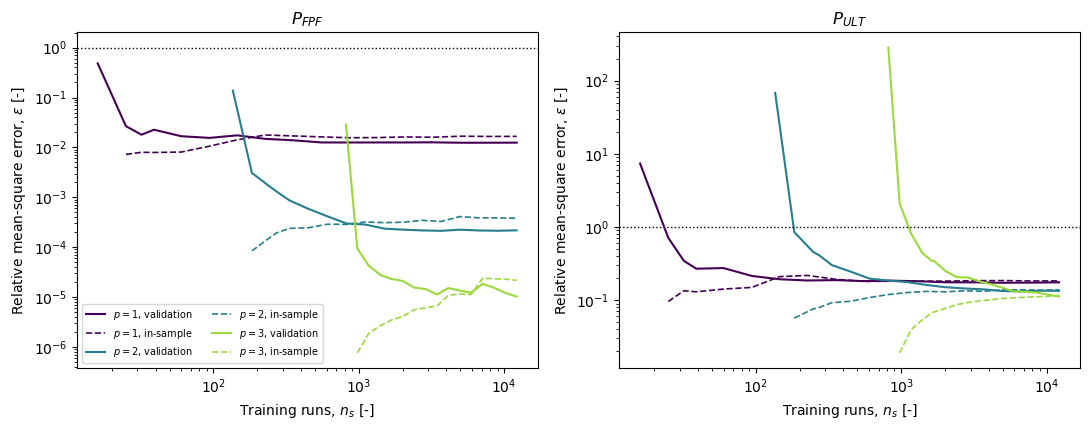

In [7]:
def bootstrap_eps(y, y_pred, seed, n_boot=2000):
    """95% bootstrap interval of epsilon over a set of runs.

    Parameters
    ----------
    y, y_pred : array of float
        Abaqus outputs and surrogate predictions at the same runs [N].
    seed : int
        Seed of the resampling stream.
    n_boot : int
        Number of resamples.

    Returns
    -------
    array of float
        The 2.5th and 97.5th percentiles of epsilon over the resamples [-].
    """
    # n_boot resamples of the run indices, with replacement, each as long as the original set.
    idx = np.random.default_rng(seed).integers(0, len(y), (n_boot, len(y)))
    # Epsilon of each resample, and its central 95% range.
    return np.percentile([relative_mse(y[i], y_pred[i]) for i in idx], [2.5, 97.5])


# Row numbers of the accepted training runs, in stream order: the first n_s of them form a nested design.
accepted_rows = np.flatnonzero(ok_train)
# For each order: the training sizes n_s and the fit at each of them.
curves = {}
for p in (1, 2, 3):
    # The number of terms P+1 of order p.
    n_terms = math.comb(p + D, D)
    # 16 sizes evenly spaced on a log axis from n_p = 1 to all accepted runs, plus n_p = 2.
    grid = np.geomspace(n_terms, len(accepted_rows), 16).round().astype(int)
    sizes = np.unique(np.append(grid, 2 * n_terms))
    curves[p] = (sizes, [fit_and_score(accepted_rows[:n_s], p) for n_s in sizes])

# Table: epsilon at n_p = 1, at n_p = 2 and with all accepted runs, for each order.
print("  p    P+1     n_s     n_p | eps validation: P_FPF    P_ULT | eps in-sample: P_FPF    P_ULT")
for p, (sizes, scores) in curves.items():
    # Where n_p = 1 and 2 sit in the sizes, and the last entry (all accepted runs); sizes[0] = P+1.
    for k in (0, int(np.flatnonzero(sizes == 2 * sizes[0])[0]), len(sizes) - 1):
        s = scores[k]
        print("%3d   %4d   %5d   %5.2f | %21.2e  %7.3f | %20.2e  %7.3f" % (p, sizes[0], sizes[k], sizes[k] / sizes[0],
              s["P_FPF"][1], s["P_ULT"][1], s["P_FPF"][2], s["P_ULT"][2]))
# The 95% bootstrap interval of the validation epsilon with all accepted runs (the same resamples for every order).
print("\n95% bootstrap interval of the validation epsilon, all accepted runs:")
for p, (sizes, scores) in curves.items():
    # Predictions of this order's fit at the validation inputs, and the interval for each output.
    psi_valid = design_matrix(xi_valid, total_order_indices(D, p))
    intervals = [bootstrap_eps(Y_valid[:, o], psi_valid @ scores[-1][name][0], seed=101) for o, name in enumerate(OUTPUTS)]
    print("  p = %d:  P_FPF %.2e - %.2e   P_ULT %.3f - %.3f" % (p, *intervals[0], *intervals[1]))

# The peak load's error against the runs per coefficient n_p, for orders 2 and 3: each order is fitted to the first n_p (P+1)
# accepted runs (all of them where the ratio asks for more), and scored on the validation runs and in-sample.
print("\nP_ULT error against n_p:       order 2                               order 3")
print("  n_p        n_s  validation  in-sample        n_s  validation  in-sample")
for n_p in (2, 4, 6, 8, 10, 12, 15):
    row = []
    for p in (2, 3):
        # The runs this order gets at this ratio, and its two errors for the peak load (the second output of fit_and_score).
        n_s = min(n_p * math.comb(p + D, D), len(accepted_rows))
        score = fit_and_score(accepted_rows[:n_s], p)["P_ULT"]
        row += [n_s, score[1], score[2]]
    print("%5d %10d %11.3f %10.3f %10d %11.3f %10.3f" % (n_p, *row))

# One colour per order, an ordered parameter on lines: viridis cut at 0.85 (series convention).
ORDER_COLOURS = plt.cm.viridis(np.linspace(0, 0.85, 3))
# One panel per output: epsilon against n_s for the three orders, validation solid, in-sample dashed.
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.4))
for ax, (name, label) in zip(axes, OUTPUTS.items()):
    for p, color in zip(curves, ORDER_COLOURS):
        # This order's sizes n_s, and its validation and in-sample epsilon at each of them.
        sizes, scores = curves[p]
        ax.plot(sizes, [s[name][1] for s in scores], "-", color=color, lw=1.5, label="$p=%d$, validation" % p)
        ax.plot(sizes[1:], [s[name][2] for s in scores[1:]], "--", color=color, lw=1.2, label="$p=%d$, in-sample" % p)
    # The mean predictor, log axes and labels.
    ax.axhline(1.0, color="k", ls=":", lw=1)
    ax.set(xscale="log", yscale="log", title=label, xlabel="Training runs, $n_s$ [-]",
           ylabel="Relative mean-square error, $\\varepsilon$ [-]")
# One legend for both panels, where the left panel has room.
axes[0].legend(loc="lower left", fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

**First-ply failure load (left).** At $n_p=1$ each fit passes through every training run, and on the validation runs
it is poor: $\varepsilon=0.48$, 0.14 and 0.029 for orders 1, 2 and 3. Then each order falls quickly to a level and
stays there: about 0.013 for order 1 from a few hundred runs, $2\times10^{-4}$ for order 2 from about 2,000 and
$1$&ndash;$2\times10^{-5}$ for order 3 from about 3,000. On that level the in-sample and validation errors are close,
so the fit is no longer chasing its training runs. What is left is the part of $P_{FPF}$ that a polynomial of that
order cannot represent, and more runs cannot remove it. Raising the order does: with all accepted runs the error falls
from 0.0124 to $2.2\times10^{-4}$ and $1.0\times10^{-5}$, by factors of about 57 and 21. At order 3 only $1.0\times10^{-3}$% of the variance is left unexplained, an rms error of about 6.5 N (9.5 N in-sample) on a spread of 2,026 N. Order 3 needs few runs per
coefficient: at $n_p=2$ it already reaches $2.4\times10^{-5}$.


One detail runs the wrong way: for orders 2 and 3 the in-sample error ends up about twice the validation one
($3.8\times10^{-4}$ against $2.2\times10^{-4}$, and $2.2\times10^{-5}$ against $1.0\times10^{-5}$), the reverse of
what chasing the training runs gives. This is NB8's lesson on small validation sets. The error of a truncated expansion
sits at rare inputs far from the centre, which 12,197 training runs contain and 100 validation runs mostly miss, so the
validation $\varepsilon$ reads low. The bootstrap interval of order 3, $0.7$&ndash;$1.5\times10^{-5}$, lies entirely
below the in-sample value.


**Peak load (right).** At $n_p=1$ the fits are far worse than predicting the mean: $\varepsilon=7.4$, 68 and 282. At
$n_p=2$ all three orders sit between 0.34 and 0.41, with in-sample errors of 0.07 to 0.14: the fits follow features
of their own training runs that do not carry over. With more runs each validation curve falls and each in-sample
curve rises towards it, and with all runs the two meet for every order: 0.175 and 0.183 for order 1, 0.134 and 0.139
for order 2, 0.113 and 0.116 for order 3. Order 3, with about 15 runs per coefficient, ends lowest, so the answer to
the question before the cell is yes: it beats order 2 by 0.021. The bootstrap intervals, 0.08&ndash;0.17
for order 3 and 0.09&ndash;0.20 for order 2, overlap, so 100 validation runs alone cannot tell the
two apart; the in-sample errors, from 12,197 runs, rank them the same way, 0.116 against 0.139.


This is why NB9 raised $n_p$ three times. The table under the cell reads the order-3 error against the runs per coefficient. At
$n_p=2$ (the first stage) the validation error was 0.34, at four (the second) 0.19 and at six 0.15; it is 0.125 at eight and
between 0.113 and 0.129 from eight to fifteen, while the in-sample error rises from 0.068 to 0.116 and meets it: at
$n_p=12$ (the third stage) the two are 0.119 and 0.113, and at 15 (the fourth, all accepted runs) 0.113 and 0.116. The last
2,400 runs, from 12 to 15 runs per coefficient, moved the validation error by 0.006 and the in-sample error by 0.003: the
order-3 error has stopped falling. Order 2 settles more slowly, 0.185 at six runs per coefficient, 0.150 at fifteen and 0.134
with all of its 90 runs per coefficient. Both columns carry the noise of 100 validation runs, which is why the in-sample
column, from thousands of runs, is the one to follow.


The pattern is the opposite of the first-ply load's. There, each order cut the error by a factor of 21 to 57; here,
the error falls only from 0.175 to 0.134 to 0.113, each order buying less than the one before: 0.041, then 0.021, an
explained share of the variance of 82.5%, 86.6% and 88.7%. At order 3 the
surrogate explains about 89% of the variance of the peak load and leaves 11% unexplained (validation; the exact in-sample budget of Part 4 gives 88% and 12%), and neither more runs (the table
above) nor a higher order seem able to remove it. In kilonewtons that is an rms error of about 0.8 kN ($\sqrt{0.11}\times2.33$ kN)
on a spread of 2.33 kN: two plates with almost the same 15 inputs can differ in their peak load by about that much in
a way no polynomial of order 3 follows. Parts 4 and 5 show what this costs: the standard deviation, the 5th percentile,
the density and the Sobol' indices of the surrogate describe the explained 89% only.
[NB11](11_smoothness_of_the_ultimate_load.ipynb) looks at why.


The **normalised parity plots** of Thapa et al. (their Fig. 8) show the result run by run: the predicted against
the Abaqus value of each validation run, both divided by the mean of the Abaqus values, so that both outputs share
one scale and a perfect surrogate lies on the diagonal. The cell draws them for the three orders, each fitted to all
accepted runs: one row per order, one column per output.

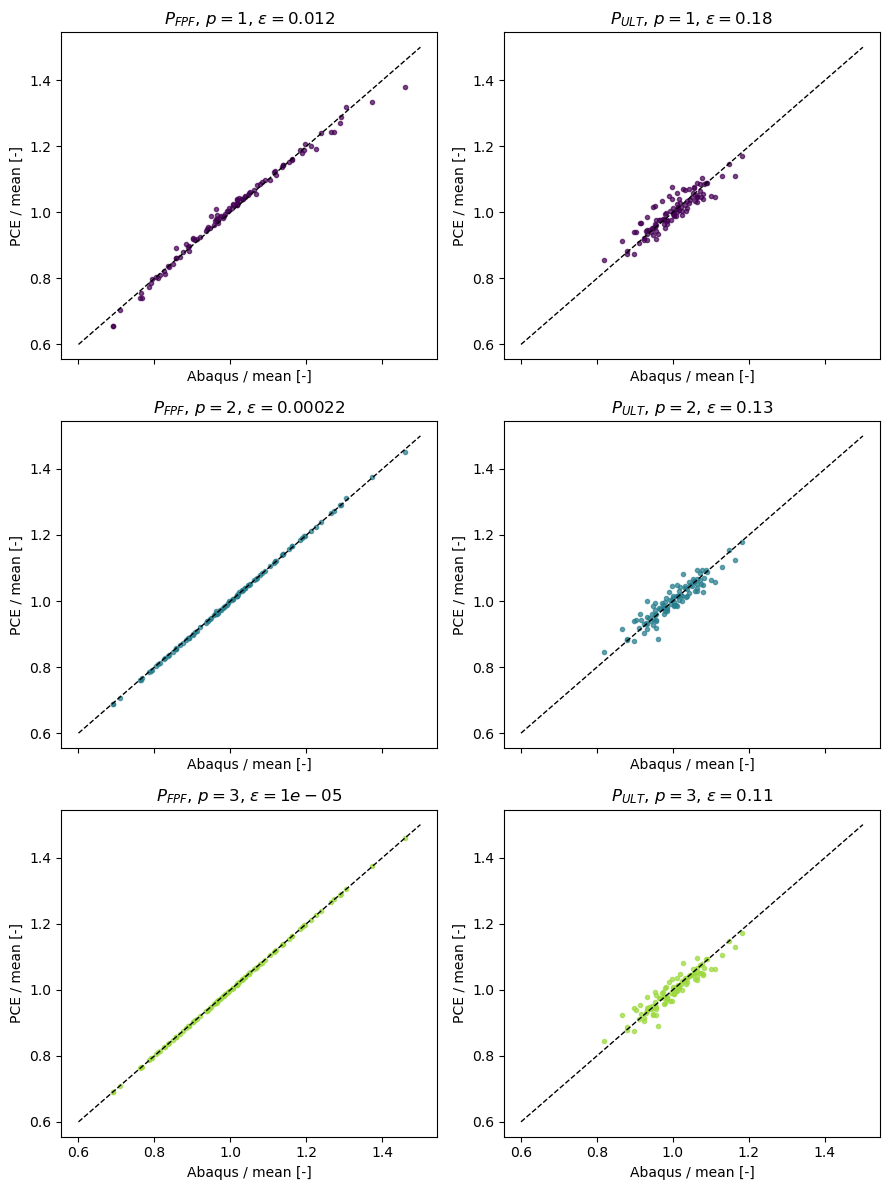

In [8]:
# One row per order, one column per output: the fit on all accepted runs (the last entry of each curve).
fig, axes = plt.subplots(3, 2, figsize=(9.0, 12.0), sharex="col", sharey="col")
for row, p in enumerate((1, 2, 3)):
    # The basis of this order at the validation inputs.
    psi_valid = design_matrix(xi_valid, total_order_indices(D, p))
    for col, (name, label) in enumerate(OUTPUTS.items()):
        # Prediction at the validation inputs, and both axes normalised by the mean of the Abaqus values.
        a, eps_val, _ = curves[p][1][-1][name]
        scale = Y_valid[:, col].mean()
        ax = axes[row, col]
        ax.plot(Y_valid[:, col] / scale, psi_valid @ a / scale, "o", ms=3, color=ORDER_COLOURS[row], alpha=0.7)
        # The diagonal a perfect surrogate would follow, title with the error, and axis labels.
        ax.plot([0.6, 1.5], [0.6, 1.5], "k--", lw=1)
        ax.set(title="%s, $p=%d$, $\\varepsilon=%.2g$" % (label, p, eps_val), xlabel="Abaqus / mean [-]",
               ylabel="PCE / mean [-]")
fig.tight_layout()
plt.show()

The rows tell the two stories of the error curves at a glance. For $P_{FPF}$ (left) the order-1 cloud is already
narrow, but bends away from the diagonal at both ends (the run at 1.46 times the mean is predicted at 1.38); orders
2 and 3 put every run on the diagonal over the whole range, 0.69 to 1.46 times the mean. For $P_{ULT}$ (right) every
order follows the diagonal, so each has the trend, and the cloud around it barely narrows from order 1 to order 3: at
order 3 a run at 0.96 times the mean is still predicted at 0.89, and one at 0.87 at 0.92. The scatter is about the same
size over the whole range, not larger at the extremes, so it is not a missing curvature that a higher order would add. The vertical spread of the cloud about the diagonal is the unexplained variance seen run by run: nearly nil for
$P_{FPF}$, an rms of about 0.8 kN for $P_{ULT}$.

### Step 2 &ndash; Are the runs with much viscous energy biased?

Part 2, Step 3 kept the 233 flagged runs, because they are too few to move the statistics of the sample much. It left
two questions that the raw runs cannot answer, because the inputs of the 233 differ from the others': is their peak
biased, and why is their spread wider? The surrogate can answer both, because it predicts a run's
$P_{ULT}$ from its inputs alone.

We fit orders 2 and 3 to the accepted training runs below 1% only, 11,964 of them. For this fit the 233 runs are new
runs, so its prediction is what their $P_{ULT}$ would be from their inputs, without a viscous bias. If their extra
viscous energy raised their peaks, Abaqus minus surrogate would be positive on average, and larger where the ratio is
larger. The next cell prints, for each order, the mean of that residual with its standard error, its median, its
correlation with the logarithm of the ratio, and the rms residual of the fitted runs as the scale of the surrogate's own
error. For order 3 it then splits the spread of three groups of runs, the fitted runs, the 100 validation runs and the
233, into what the surrogate explains and what it does not. Last, it plots the order-3 residual of every run against its
ratio.


accepted training runs: 11964 below 1%, 233 at 1% or more; 0 validation runs at 1% or more
  p | mean residual of the 233 [N]  (s.e.)  [% of their mean P_ULT] | median [N] | corr. with log ratio | rms of fitted runs [N]


  2 |                         57       91                 0.16 %   |        108 |                 0.13 |                  856


  3 |                        -12       82                -0.04 %   |        128 |                 0.04 |                  786



order 3, fitted without the 233:                n | std Abaqus | std surrogate | rms residual [kN] | unexplained share


  fitted runs (below 1%)          11964 |      2.321 |         2.184 |             0.786 |             0.115
  validation runs                   100 |      2.319 |         2.143 |             0.793 |             0.117
  the 233 runs                      233 |      2.753 |         2.554 |             1.246 |             0.205


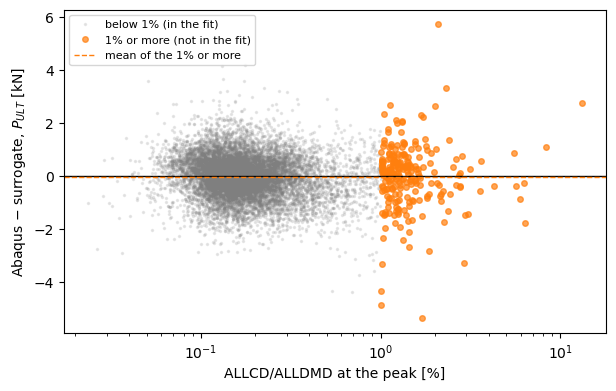

In [9]:
# The accepted training runs at 1% or more (the 233), and those below 1% (the fit without them uses these).
rows_high = np.flatnonzero(ok_train & (ratio_train >= 0.01))
rows_low = np.flatnonzero(ok_train & (ratio_train < 0.01))
print("accepted training runs: %d below 1%%, %d at 1%% or more; %d validation runs at 1%% or more"
      % (len(rows_low), len(rows_high), (ratio_valid >= 0.01).sum()))

# For orders 2 and 3: fit P_ULT without the 233 runs, then the residual Abaqus - surrogate [N] at them and at the fitted runs.
residual = {}
print("  p | mean residual of the 233 [N]  (s.e.)  [% of their mean P_ULT] | median [N] | corr. with log ratio | rms of fitted runs [N]")
for p in (2, 3):
    # The basis, and the coefficients of P_ULT fitted on the runs below 1% (output 1 of fit_and_score's dictionary).
    alphas = total_order_indices(D, p)
    a = fit_and_score(rows_low, p)["P_ULT"][0]
    # Abaqus minus surrogate at the 233 runs (not in the fit) and at the runs below 1% (in the fit) [N].
    res_high = Y_train[rows_high, 1] - design_matrix(xi_train[rows_high], alphas) @ a
    res_low = Y_train[rows_low, 1] - design_matrix(xi_train[rows_low], alphas) @ a
    residual[p] = (res_high, res_low)
    # The mean residual, its standard error, and it as a share of the mean peak load of the 233 runs.
    se = res_high.std(ddof=1) / np.sqrt(len(res_high))
    print("%3d | %26.0f %8.0f %20.2f %%   | %10.0f | %20.2f | %20.0f"
          % (p, res_high.mean(), se, 100 * res_high.mean() / Y_train[rows_high, 1].mean(), np.median(res_high),
             np.corrcoef(res_high, np.log10(ratio_train[rows_high]))[0, 1], np.sqrt(np.mean(res_low ** 2))))

# The same order-3 fit, now asked how much of each group's spread it explains: for the fitted runs, the 100 validation runs and
# the 233 (the last two are not in the fit, so they are the fair pair to compare). Per group, the standard deviation of the
# Abaqus P_ULT, of the surrogate at the group's inputs and the rms residual [kN], and epsilon, the share of the group's variance
# that the surrogate does not follow (NB8).
a3 = fit_and_score(rows_low, 3)["P_ULT"][0]
print("\norder 3, fitted without the 233:                n | std Abaqus | std surrogate | rms residual [kN] | unexplained share")
for label, xi, y in (("fitted runs (below 1%)", xi_train[rows_low], Y_train[rows_low, 1]),
                     ("validation runs", xi_valid, Y_valid[:, 1]),
                     ("the 233 runs", xi_train[rows_high], Y_train[rows_high, 1])):
    # The surrogate at this group's inputs [N], then the five numbers of the row.
    pred = design_matrix(xi, total_order_indices(D, 3)) @ a3
    print("  %-24s %12d | %10.3f | %13.3f | %17.3f | %17.3f"
          % (label, len(y), y.std() / 1e3, pred.std() / 1e3, np.sqrt(np.mean((y - pred) ** 2)) / 1e3, relative_mse(y, pred)))

# The order-3 residual of every run against its ratio: the fitted runs in grey, the 233 in orange [kN against %].
res_high, res_low = residual[3]
fig, ax = plt.subplots(figsize=(7.0, 4.2))
ax.plot(100 * ratio_train[rows_low], res_low / 1e3, "o", color="C7", ms=1.5, alpha=0.15, label="below 1% (in the fit)")
ax.plot(100 * ratio_train[rows_high], res_high / 1e3, "o", color="C1", ms=4, alpha=0.7, label="1% or more (not in the fit)")
# Zero, and the mean residual of the 233 runs.
ax.axhline(0.0, color="k", lw=1)
ax.axhline(res_high.mean() / 1e3, color="C1", ls="--", lw=1, label="mean of the 1% or more")
ax.set(xscale="log", xlabel="ALLCD/ALLDMD at the peak [%]", ylabel="Abaqus $-$ surrogate, $P_{ULT}$ [kN]")
ax.legend(loc="upper left", fontsize=8)
plt.show()

Without the 233 runs, the surrogate puts them where they are. At order 3 their mean residual is $-12$ N, with a standard
error of 82 N ($-0.04$% of their mean peak load); at order 2 it is $+57$ N, with 91 N (0.16%). Both lie within one standard
error of zero, and the medians, 128 and 108 N, are 1.6 and 1.2 standard errors from it. The residual does not grow with the ratio: its
correlation with the logarithm of the ratio is 0.04 and 0.13, weak next to the 786 and 856 N rms scatter of the fitted runs. In the plot, the orange points are centred on zero, even at ratios of 5% and more, but they spread wider than the grey ones.

The test has a scale. A rise of 1% of $P_{ULT}$, about 350 N, would be more than four standard errors at order 3, so it
would show; a few tenths of a percent would not. It also compares the 233 runs with the others, whose own ratio is small
(median 0.17%), so a bias common to all runs at $\eta=10^{-4}$ is not tested here; that takes another viscosity, as in
NB6. What the test shows is that the bursts do not push the peaks of these runs above the rest.


**The spread is the other result.** The 233 runs are not in the fit, and neither are the 100 validation runs, so the
validation runs are the fair comparison. The surrogate leaves 0.117 of the variance of the validation runs unexplained
(rms residual 0.79 kN) but 0.205 of the variance of the 233 (rms 1.25 kN, 1.6 times as much). Their wider raw spread,
2.75 kN against 2.32 kN, therefore has two parts. The surrogate's own spread at their inputs is larger too, 2.55 kN
against 2.14&ndash;2.18 kN, so their inputs reach further out, as NB9 found. And what the surrogate cannot follow is
larger. This is a roughness, not a bias, and the test does not say why the 233 are rougher; the timing of the collapse,
which [NB11](11_smoothness_of_the_ultimate_load.ipynb) finds to be the rough part, is a candidate. As 1.9% of the
sample, they raise the residual variance of the fit by only about 3%.


The same check from the other side is the fit of Step 1 on all accepted runs, with the 233. The next cell sets the two fits side by side for orders 2 and 3:
the error $\varepsilon$ of both loads on the 100 validation runs, none of which reaches 1%, so they judge both fits on
the same ground, and in-sample, and the mean and standard deviation of $P_{ULT}$ that each surrogate gives, read from the
coefficients as in NB8 (the mean is $a_0$). The raw statistics without and with the 233 are in Part 2, Step 3.

In [10]:
print("  p   training set           n_s | eps validation: P_FPF    P_ULT | eps in-sample: P_FPF    P_ULT | P_ULT mean, std [kN]")
for p in (2, 3):
    # The basis, and E[psi^2] of each term, for the mean and the standard deviation from the coefficients.
    alphas = total_order_indices(D, p)
    norms = basis_norms(alphas)
    # The fit without the runs at 1% or more (Step 2), and the fit on all accepted runs (Step 1).
    for label, rows in (("below 1% only", rows_low), ("all accepted", np.flatnonzero(ok_train))):
        s = fit_and_score(rows, p) if label == "below 1% only" else curves[p][1][-1]
        # The mean a_0 and the standard deviation sqrt(sum_j a_j^2 E[psi_j^2]) of the P_ULT surrogate [N].
        a = s["P_ULT"][0]
        print("%3d   %-15s %10d | %21.2e  %7.3f | %20.2e  %7.3f | %9.3f %6.3f"
              % (p, label, len(rows), s["P_FPF"][1], s["P_ULT"][1], s["P_FPF"][2], s["P_ULT"][2],
                 a[0] / 1e3, np.sqrt(np.sum(a[1:] ** 2 * norms[1:])) / 1e3))

  p   training set           n_s | eps validation: P_FPF    P_ULT | eps in-sample: P_FPF    P_ULT | P_ULT mean, std [kN]


  2   below 1% only        11964 |              2.11e-04    0.138 |             3.60e-04    0.136 |    35.363  2.171
  2   all accepted         12197 |              2.18e-04    0.134 |             3.80e-04    0.139 |    35.364  2.165


  3   below 1% only        11964 |              9.05e-06    0.117 |             2.16e-05    0.115 |    35.358  2.199
  3   all accepted         12197 |              1.03e-05    0.113 |             2.18e-05    0.116 |    35.356  2.200


Including the 233 runs changes the validation error of the peak load little: from 0.138 to 0.134 at order 2 and from
0.117 to 0.113 at order 3, a small fall, as expected from 2% more runs. The in-sample error moves by 0.003 or less. For
the first-ply load, which they cannot affect, the change is within the scatter of a refit. The statistics move even less:
the surrogate's mean peak load is 35.363 and 35.364 kN at order 2 and 35.358 and 35.356 kN at order 3, and its standard
deviation 2.171 and 2.165, 2.199 and 2.200 kN (without and with the 233). This is what Part 2 predicted for 1.9% of the
runs, and it holds although their unexplained scatter is larger, because they add only about 3% to the residual variance.
We keep all 12,197 accepted runs, with NB9's flag still in the result files.


## Part 4 &ndash; The uncertainty of the two loads from the surrogate

The surrogate was built to answer questions about the output's distribution without new Abaqus runs: the mean, the standard
deviation and the 5th percentile of each load, the percentile a design allowable looks at (NB2), and the density. Part 2 gave
the raw Abaqus values of all of these, so here we can check the surrogates against them. Step 1 sets the surrogates' mean,
standard deviation and 5th percentile beside the raw ones, and Step 2 their densities.

### Step 1 &ndash; Mean, standard deviation and 5th percentile: surrogate against Abaqus

NB8 (Part 2, Step 2) showed that the coefficients give the surrogate's mean and standard deviation directly, with no sampling,

$$\mu_{PCE}=a_0,\qquad \sigma_{PCE}^2=\sum_{j=1}^{P}a_j^2\,\mathrm E[\psi_j^2],$$

where $\mu_{PCE}$ and $\sigma_{PCE}$ are the mean and standard deviation of the surrogate [N], $a_j$ are the coefficients and $\mathrm E[\psi_j^2]=\prod_i\alpha_i!$ (`basis_norms`) is the mean square of term $j$.

A percentile has no such formula. For it we do what the surrogate is for: draw $10^5$ random inputs (seed 9), evaluate the surrogate at all of them, which costs a fraction of a second where Abaqus would need years, and read the 5th percentile of the values. The same sample gives the density in Step 2. The raw side is the Abaqus sample of Part 2 with the statistics and 95% bootstrap intervals of its Step 2.

The cell prints both in the layout of [Thapa et al. (2021, Table 3)](https://doi.org/10.1007/s00158-020-02690-5): one block per method, the surrogates of orders 1 to 3 below the Abaqus runs, with their difference from the Abaqus value in brackets. Their table has the mean and the standard deviation; the 5th percentile is added. A caution first: the surrogates were fitted to 12,197 of these 12,297 runs, so the two sides are not independent, as they were for Thapa et al., whose 5,000 Latin hypercube runs were separate from the 306 that fitted the surrogate. What that sharing can and cannot hide is checked after the table, with two halves of the runs. The cells after the table add the variance budget of the order-3 surrogate, which the comments use.

In [11]:
# A large random sample of the standardised inputs (seed 9), never used for fitting.
N_MC, SEED_MC = 100_000, 9
xi_mc = np.random.default_rng(SEED_MC).standard_normal((N_MC, D))
# The order-3 basis and the coefficients of both loads (Part 5 reads them).
alphas_3 = total_order_indices(D, 3)
coeffs_3 = np.column_stack([curves[3][1][-1][name][0] for name in OUTPUTS])
# For each order: the surrogate's values at the 10^5 inputs [N] and its exact mean and standard deviation [N].
Y_mc, mu_pce, sd_pce = {}, {}, {}
for p in (1, 2, 3):
    # The basis and the coefficients of this order, fitted on all accepted runs (Part 3): one column per load.
    alphas = total_order_indices(D, p)
    coeffs = np.column_stack([curves[p][1][-1][name][0] for name in OUTPUTS])
    # The values at the sample, 10,000 rows at a time to keep the design matrix small.
    Y_mc[p] = np.vstack([design_matrix(chunk, alphas) @ coeffs for chunk in np.array_split(xi_mc, N_MC // 10_000)])
    # The mean a_0 and the standard deviation sqrt(sum a_j^2 E[psi_j^2]) from the coefficients.
    mu_pce[p] = coeffs[0]
    sd_pce[p] = np.sqrt(np.sum(coeffs[1:] ** 2 * basis_norms(alphas)[1:, None], axis=0))

# The raw statistics (STATS, raw) are those of Part 2, Step 2.
# The surrogate's statistics: exact mean and standard deviation, and the 5th percentile of the sample [N].
pce = {(name, p): {"mean": mu_pce[p][o], "std": sd_pce[p][o], "Q5%": np.percentile(Y_mc[p][:, o], 5)}
       for o, name in enumerate(OUTPUTS) for p in (1, 2, 3)}

# Header, then per load the Abaqus row (estimate and 95% interval) and one row per order (value and difference).
print("%-6s %-20s %17s %17s %17s" % ("load", "source [kN]", "mean", "std", "5th percentile"))
for name in OUTPUTS:
    print("%-6s %-20s %s" % (name, "Abaqus, %d runs" % n_raw, " ".join(
        "%6.3f [%5.2f,%5.2f]" % (raw[name, s]["estimate"] / 1e3, raw[name, s]["ci_low"] / 1e3, raw[name, s]["ci_high"] / 1e3)
        for s in STATS)))
    for p in (1, 2, 3):
        print("%-6s %-20s %s" % ("", "PCE, order %d" % p, " ".join(
            "%6.3f (%+6.2f%%)  " % (pce[name, p][s] / 1e3, 100 * (pce[name, p][s] / raw[name, s]["estimate"] - 1)) for s in STATS)))


load   source [kN]                       mean               std    5th percentile
P_FPF  Abaqus, 12297 runs   12.238 [12.20,12.27]  2.026 [ 2.00, 2.05]  9.183 [ 9.13, 9.23]
       PCE, order 1         12.241 ( +0.02%)    2.021 ( -0.23%)    8.918 ( -2.88%)  
       PCE, order 2         12.241 ( +0.02%)    2.040 ( +0.68%)    9.169 ( -0.15%)  
       PCE, order 3         12.241 ( +0.02%)    2.040 ( +0.69%)    9.170 ( -0.14%)  
P_ULT  Abaqus, 12297 runs   35.378 [35.33,35.42]  2.331 [ 2.30, 2.36] 31.481 [31.40,31.58]
       PCE, order 1         35.370 ( -0.02%)    2.116 ( -9.21%)   31.857 ( +1.19%)  
       PCE, order 2         35.364 ( -0.04%)    2.165 ( -7.12%)   31.735 ( +0.81%)  
       PCE, order 3         35.356 ( -0.06%)    2.200 ( -5.63%)   31.669 ( +0.59%)  


Two printouts back the comments on the table. The **variance budget** splits the variance of each load, over the 12,197 fitted runs, into what the order-3 surrogate explains and what stays in the residual, and sets beside it the surrogate's own variance from the coefficients, $\sigma_{PCE}^2$. The second printout shows the mean: how far $a_0$ sits from the mean of the fitted runs, for NB8's normal equation to explain.

In [12]:
# The variance budget of the order-3 surrogate on the 12,197 fitted runs [kN^2]. Least squares leaves a residual with zero mean
# and no correlation with the surrogate, so the Abaqus variance is exactly the variance of the surrogate at the run inputs
# (explained) plus the variance of the residual (unexplained). sigma^2_PCE, from the coefficients, is the surrogate's variance
# over the whole input distribution instead of over these 12,197 draws.
# The inputs of the fitted runs and the order-3 basis evaluated at them.
xi_fit = xi_train[ok_train]
psi_fit = design_matrix(xi_fit, alphas_3)
print("\nvariance budget of the order-3 surrogate, 12,197 fitted runs [kN^2]")
print("%-6s %8s | %9s %9s %6s | %9s %6s" % ("load", "Abaqus", "explained", "residual", "share", "sigma2_PCE", "ratio"))
for o, name in enumerate(OUTPUTS):
    # The surrogate at the run inputs and the residual [N]; their variances add up to the Abaqus variance.
    y = Y_train[ok_train, o]
    pred = psi_fit @ coeffs_3[:, o]
    # Abaqus, explained, residual and share, sigma^2_PCE and its ratio to the Abaqus variance [kN^2].
    print("%-6s %8.3f | %9.3f %9.3f %5.1f%% | %9.3f %6.3f" % (name, y.var() / 1e6, pred.var() / 1e6, (y - pred).var() / 1e6,
          100 * pred.var() / y.var(), sd_pce[3][o] ** 2 / 1e6, sd_pce[3][o] ** 2 / y.var()))

# The mean of the surrogate: a_0 is the mean of the fitted runs minus a correction, sum_j a_j mean(psi_j), the average of the
# polynomial terms over the 12,197 draws, which would be 0 over the whole distribution. Differences in N.
print("\nmean of the fitted runs, a_0 and the correction [N]; standard error of the mean of the runs")
for o, name in enumerate(OUTPUTS):
    # The runs of this load, and the correction a_0 - mean = -sum_j a_j mean(psi_j) [N].
    y = Y_train[ok_train, o]
    corr = psi_fit[:, 1:].mean(axis=0) @ coeffs_3[1:, o]
    # The mean, a_0, their difference, the correction (equal to it) and the standard error of the mean.
    print("%-6s mean %9.1f   a_0 %9.1f   a_0 - mean %7.1f   -correction %7.1f   s.e. of the mean %5.1f"
          % (name, y.mean(), coeffs_3[0, o], coeffs_3[0, o] - y.mean(), -corr, y.std(ddof=1) / np.sqrt(len(y))))



variance budget of the order-3 surrogate, 12,197 fitted runs [kN^2]
load     Abaqus | explained  residual  share | sigma2_PCE  ratio
P_FPF     4.108 |     4.108     0.000 100.0% |     4.161  1.013
P_ULT     5.431 |     4.801     0.630  88.4% |     4.838  0.891

mean of the fitted runs, a_0 and the correction [N]; standard error of the mean of the runs
P_FPF  mean   12238.1   a_0   12241.3   a_0 - mean     3.1   -correction     3.1   s.e. of the mean  18.4
P_ULT  mean   35380.7   a_0   35356.2   a_0 - mean   -24.5   -correction   -24.5   s.e. of the mean  21.1


**The means agree, and are bound to.** Every order reproduces the Abaqus mean of both loads to within 0.06%, inside the Abaqus interval (12.24 against 12.20&ndash;12.27 kN for $P_{FPF}$, 35.36 against 35.33&ndash;35.42 kN for $P_{ULT}$). This is the weakest of the three tests, because the constant term of a least-squares fit is fitted to the mean of the runs. Its first normal equation (NB8) reads $\bar y=a_0+\sum_{j\ge1}a_j\bar\psi_j$, where $\bar y$ is the mean of the fitted runs and $\bar\psi_j$ the average of term $j$ over their inputs, which over the whole input distribution would be 0. So $a_0$ is the mean of the runs minus a correction, the sampling error that the polynomial can see: $-24.5$ N for $P_{ULT}$, against a standard error of the mean of 21 N, and $+3$ N for $P_{FPF}$ (the last printout). This is the control-variable estimator of [Rubinstein & Kroese (2016, §5.3)](https://doi.org/10.1002/9781118631980), with the polynomial terms as controls. The agreement of the means checks the arithmetic of the fit, not the model.


**The standard deviation tells the loads apart.** For $P_{FPF}$ the order-2 and order-3 values, both 2.040 kN, are 0.7% above the Abaqus 2.026 kN, inside its interval (2.00&ndash;2.05 kN), about one standard error of the Abaqus value (0.014 kN). The variance budget says where the difference comes from. The surrogate explains all of the variance of the fitted $P_{FPF}$ runs (4.108 of 4.108 kN$^2$), but its variance over the whole input distribution, from the coefficients, is 4.161 kN$^2$, 1.3% above that of the runs (0.65% in standard deviation). The 12,197 draws of the inputs happened to spread slightly less than the distribution in the directions that matter, and Abaqus follows them; the surrogate's value does not depend on the draws. So the difference lies with the sample, not with the surrogate.


For $P_{ULT}$ every order is below the Abaqus interval (2.30&ndash;2.36 kN): $-9.2\%$, $-7.1\%$ and $-5.6\%$ at orders 1 to 3. The budget shows why. Of the 5.431 kN$^2$ variance of the fitted runs the order-3 surrogate explains 4.801 kN$^2$ (88.4%) and leaves 0.630 kN$^2$ (11.6%) in the residual; its coefficient variance, 4.838 kN$^2$ (89.1% of the Abaqus variance), is the explained part. The surrogate's standard deviation is the square root of the explained variance alone, 2.200 kN against 2.331 kN, 94% of the true spread, the $\sqrt{1-\varepsilon}=0.94$ of Part 3. It is the effect [Chantrasmi et al. (2009, p. 7171)](https://doi.org/10.1016/j.jcp.2009.06.024) report for a smoothed reconstruction of a discontinuous response.


**The 5th percentile follows the same split.** For $P_{FPF}$, order 1 is 2.9% low (8.92 kN), outside the Abaqus interval (9.13&ndash;9.23 kN), and orders 2 and 3 are within 0.15% (9.17 kN), inside it. For $P_{ULT}$ the surrogate's 5th percentile is **too high**: 31.86, 31.74 and 31.67 kN at orders 1 to 3 against 31.48 kN, so order 3 is 0.19 kN (0.59%) above the Abaqus value and above the top of its interval (31.58 kN). It is the unsafe direction for a design allowable, which looks for a low strength. The size is what the unexplained variance predicts: the 5th percentile lies $(35.378-31.481)/2.331=1.67$ standard deviations below the mean, and $1.67\times(2.331-2.200)=0.22$ kN. (The surrogate's own sampling error, from $10^5$ points, is about 0.015 kN by NB2's formula, so the 0.19 kN is not noise.)

For the first-ply load, then, a surrogate of order 2 or 3 gives the mean, the standard deviation and the 5th percentile of the Abaqus runs; for the peak load it gives the mean to 0.06%, the 5th percentile to 0.6% on the unsafe side and the standard deviation to 6% low, all because it follows 89% of the variance and none of the other 11%.

In the layout of Thapa et al.'s Table 3, with the differences from the Abaqus values in brackets (from the cell above):

| | | $P_{FPF}$ [kN] | $P_{ULT}$ [kN] |
|---|---|---|---|
| Abaqus, 12,297 runs | Mean | 12.238 | 35.378 |
| | Std | 2.026 | 2.331 |
| | 5th percentile | 9.183 | 31.481 |
| PCE, order 1 | Mean | 12.241 (+0.02%) | 35.370 (&minus;0.02%) |
| | Std | 2.021 (&minus;0.23%) | 2.116 (&minus;9.21%) |
| | 5th percentile | 8.918 (&minus;2.88%) | 31.857 (+1.19%) |
| PCE, order 2 | Mean | 12.241 (+0.02%) | 35.364 (&minus;0.04%) |
| | Std | 2.040 (+0.68%) | 2.165 (&minus;7.12%) |
| | 5th percentile | 9.169 (&minus;0.15%) | 31.735 (+0.81%) |
| PCE, order 3 | Mean | 12.241 (+0.02%) | 35.356 (&minus;0.06%) |
| | Std | 2.040 (+0.69%) | 2.200 (&minus;5.63%) |
| | 5th percentile | 9.170 (&minus;0.14%) | 31.669 (+0.59%) |

[Thapa et al. (2021, Table 3)](https://doi.org/10.1007/s00158-020-02690-5) found their PCE and Latin hypercube statistics equal to three digits for both loads; here only the first-ply load comes close (a mean to 0.02%, a standard deviation to 0.7% and a 5th percentile to 0.15% at order 2 or 3).

**Is it fair to compare with the runs the surrogate was fitted to?** In Thapa et al.'s study the reference, 5,000 Latin hypercube runs, was independent of the 306 that fitted the surrogate. Ours is not: 12,197 of the 12,297 runs were fitted. Two things limit what that can do. The 5th percentile and the density come from fresh inputs (seed 9), never from the training points, so a surrogate that had only learnt its training runs would show it. And a shared sample can only correlate the sampling errors of the two sides, which makes them agree; it can hide a difference but not create one. To check that it hides nothing, the next cell cuts the 12,297 runs into two halves of 6,148 and 6,149, fits order 3 to each half, and compares each surrogate's statistics with the raw ones of the half it was fitted to and of the other half, which it never saw. With half the runs each fit has about 7.5 runs per coefficient instead of fifteen, so its numbers differ a little from the table above.


In [13]:
# The raw runs in stream order (the 12,197 accepted training runs, then the 100 validation runs) with their standardised inputs.
X_raw = np.vstack([xi_train[ok_train], xi_valid])
# Two halves of about 6,150 runs (row numbers); the first half is the start of NB9's stream.
halves = {"first half": np.arange(n_raw // 2), "second half": np.arange(n_raw // 2, n_raw)}
# E[psi^2] of the order-3 terms, for the standard deviation from the coefficients.
norms_3 = basis_norms(alphas_3)
# For each load and each half: the surrogate's statistics [N] and the raw ones of the same half, in STATS order (mean, std, Q5%).
pce_half, raw_half = {}, {}
for o, name in enumerate(OUTPUTS):
    for h, rows in halves.items():
        # Fit order 3 to this half only, and evaluate the surrogate at the 10^5 inputs of Step 1, 10,000 rows at a time.
        a = fit_pce(X_raw[rows], Y_raw[rows, o], alphas_3)
        y_mc = np.concatenate([design_matrix(chunk, alphas_3) @ a for chunk in np.array_split(xi_mc, N_MC // 10_000)])
        # The surrogate: mean a_0, standard deviation sqrt(sum a_j^2 E[psi_j^2]), and the 5th percentile of the sample.
        pce_half[name, h] = np.array([a[0], np.sqrt(np.sum(a[1:] ** 2 * norms_3[1:])), np.percentile(y_mc, 5)])
        # The raw runs of the same half: mean, standard deviation (n - 1) and 5th percentile.
        raw_half[name, h] = np.array([Y_raw[rows, o].mean(), Y_raw[rows, o].std(ddof=1), np.percentile(Y_raw[rows, o], 5)])

# One row per load, fitted half and statistic: the surrogate [kN], and its difference from the raw value of the half it was
# fitted to and of the other half (which it never saw).
print("%-6s %-12s %-5s %8s | %-22s | %-22s" % ("load", "fitted on", "stat", "PCE [kN]", "raw, same half [kN]", "raw, other half [kN]"))
for name in OUTPUTS:
    for h, other in (("first half", "second half"), ("second half", "first half")):
        for k, s in enumerate(STATS):
            # The surrogate's value, and the raw value of the same half and of the other half [N].
            v, same, oth = pce_half[name, h][k], raw_half[name, h][k], raw_half[name, other][k]
            print("%-6s %-12s %-5s %8.3f | %8.3f (%+6.2f%%)     | %8.3f (%+6.2f%%)"
                  % (name, h, s, v / 1e3, same / 1e3, 100 * (v / same - 1), oth / 1e3, 100 * (v / oth - 1)))


load   fitted on    stat  PCE [kN] | raw, same half [kN]    | raw, other half [kN]  
P_FPF  first half   mean    12.241 |   12.240 ( +0.01%)     |   12.237 ( +0.04%)
P_FPF  first half   std      2.040 |    2.023 ( +0.84%)     |    2.029 ( +0.56%)
P_FPF  first half   Q5%      9.170 |    9.160 ( +0.11%)     |    9.217 ( -0.50%)
P_FPF  second half  mean    12.241 |   12.237 ( +0.04%)     |   12.240 ( +0.01%)
P_FPF  second half  std      2.040 |    2.029 ( +0.54%)     |    2.023 ( +0.82%)
P_FPF  second half  Q5%      9.169 |    9.217 ( -0.51%)     |    9.160 ( +0.10%)
P_ULT  first half   mean    35.364 |   35.389 ( -0.07%)     |   35.367 ( -0.01%)
P_ULT  first half   std      2.212 |    2.348 ( -5.81%)     |    2.313 ( -4.39%)
P_ULT  first half   Q5%     31.672 |   31.431 ( +0.77%)     |   31.543 ( +0.41%)
P_ULT  second half  mean    35.356 |   35.367 ( -0.03%)     |   35.389 ( -0.09%)
P_ULT  second half  std      2.218 |    2.313 ( -4.10%)     |    2.348 ( -5.52%)
P_ULT  second half  Q5% 

Against the other half the picture is the same as against the half each surrogate was fitted to. For $P_{ULT}$ the standard deviation is 4.4% and 5.5% low (5.8% and 4.1% against the same half), and the 5th percentile 0.41% and 0.57% high (0.77% and 0.22%). The discrepancies of the full table, 5.6% and 0.59%, therefore appear with independent data. The two comparisons differ by less than the sampling noise of the halves themselves (the raw standard deviations of the halves differ by about 1.5%). Sharing runs did not make the surrogate look better.

The mean shows the built-in agreement: the two fits give $a_0=35.364$ and 35.356 kN, while the raw means of the halves are 35.389 and 35.367 kN. For $P_{FPF}$ both surrogates give the same standard deviation, 2.040 kN, while the raw halves give 2.023 and 2.029 kN. The surrogate's value does not move with the sample and the raw one does, which supports reading the 0.7% gap as a property of the sample.

An independent reference matters when the training runs are too few to be a Monte Carlo reference themselves, as Thapa et al.'s 306 were. Half of our runs already form a converged reference (Part 2, Step 1), so the 12,297 are one.


### Step 2 &ndash; The density of each load

The density shows more than three numbers. For the surrogate we take the order-3 values at the $10^5$ points of Step 1 and smooth them with NB2's kernel density estimate. For the raw runs we draw their histogram and their own kernel density estimate.

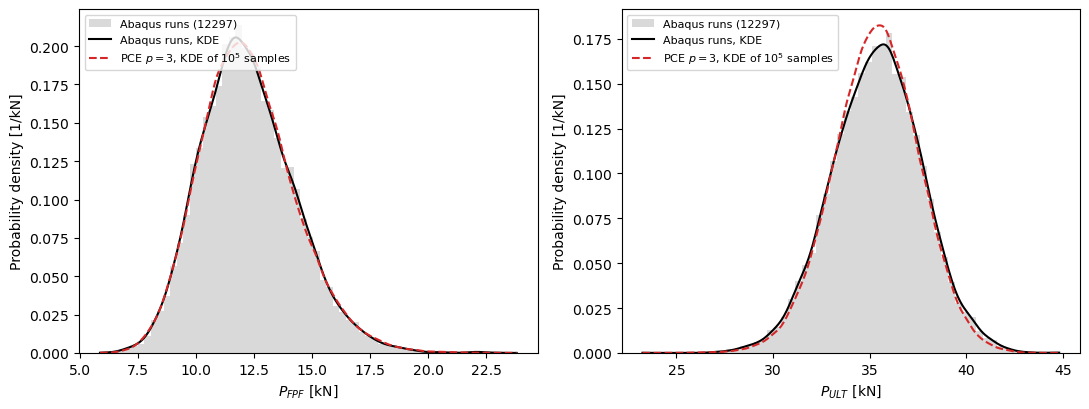

In [14]:
# One panel per load.
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2))
for o, (ax, (name, label)) in enumerate(zip(axes, OUTPUTS.items())):
    # A grid over both samples [kN], the raw histogram, and the two density estimates.
    grid = np.linspace(min(Y_raw[:, o].min(), Y_mc[3][:, o].min()), max(Y_raw[:, o].max(), Y_mc[3][:, o].max()), 400) / 1e3
    ax.hist(Y_raw[:, o] / 1e3, bins=60, density=True, color="0.85", label="Abaqus runs (%d)" % n_raw)
    ax.plot(grid, gaussian_kde(Y_raw[:, o] / 1e3)(grid), "k-", lw=1.5, label="Abaqus runs, KDE")
    ax.plot(grid, gaussian_kde(Y_mc[3][:, o] / 1e3)(grid), "C3--", lw=1.5, label="PCE $p=3$, KDE of $10^5$ samples")
    # Labels and legend.
    ax.set(xlabel="%s [kN]" % label, ylabel="Probability density [1/kN]")
    ax.legend(loc="upper left", fontsize=8)
# Arrange the panels without overlaps.
fig.tight_layout()
plt.show()

The densities show the same thing in shape. For $P_{FPF}$ (left) the two curves lie on top of each other over the whole
range, 6 to 23 kN, including the long upper tail. For $P_{ULT}$ (right) the surrogate's density has the right centre
and shape but is narrower: its peak is higher (0.18 against 0.17 per kN) and both its tails fall off earlier, below
about 31 kN and above about 39 kN. As Step 1 showed, the 5th percentile of the peak load read from the surrogate, the value a design allowable
would use, comes out 0.19 kN (0.6%) too close to the mean, on the unsafe side. The surrogate gives the density of the explained 89% of the variance of the peak load; the unexplained 11% is what would widen it to the Abaqus one.

## Part 5 &ndash; Sobol' indices from the surrogate

Which inputs drive each load? [NB5](05_sobol_indices.ipynb) answered this for two inputs with a pick-freeze Monte
Carlo study, and NB8 (Part 2, Step 6) showed that a PCE gives the same first-order and total indices for free, by
grouping the variance shares $a_j^2\,\mathrm E[\psi_j^2]$ of its terms by the inputs each term contains. The cell
applies NB8's `sobol_indices` to the order-3 coefficients of both loads and draws them as bars: the first-order index
$S_i$ (input $i$ alone) and the total index $S_i^{\mathrm{tot}}$ (with every interaction it takes part in).

Remember NB8's caveat: the indices are shares of the surrogate's own variance. For $P_{ULT}$ that is the 89% of the
variance the order-3 surrogate explains (Part 3); the rest is not shared out.

P_FPF: Y_T 0.358/0.365, E2 0.341/0.347, E1 0.287/0.293; sum of S_i = 0.991
P_ULT: E1 0.502/0.522, G_fT 0.344/0.354, X_T 0.077/0.101, nu12 0.010/0.018, Y_T 0.002/0.015, E2 0.002/0.012, G12 0.002/0.011, S_L 0.002/0.011; sum of S_i = 0.945


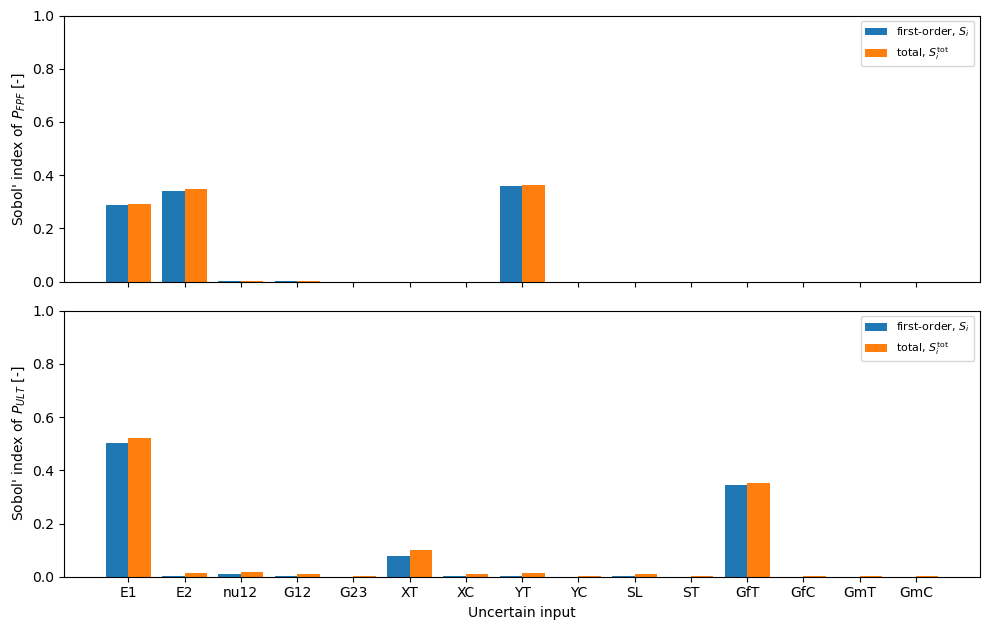

In [15]:
# First-order and total indices of each load, from its order-3 coefficients.
sobol = {name: sobol_indices(coeffs_3[:, o], alphas_3) for o, name in enumerate(OUTPUTS)}
# One panel per load, sharing the input axis; the bar positions.
fig, axes = plt.subplots(2, 1, figsize=(10.0, 6.4), sharex=True)
pos = np.arange(D)
for ax, (name, label) in zip(axes, OUTPUTS.items()):
    # Two bars per input: first-order and total index.
    s, s_tot = sobol[name]
    ax.bar(pos - 0.2, s, 0.4, color="C0", label="first-order, $S_i$")
    ax.bar(pos + 0.2, s_tot, 0.4, color="C1", label="total, $S_i^{\\mathrm{tot}}$")
    # Labels, the index range 0-1, and a legend.
    ax.set(ylabel="Sobol' index of %s [-]" % label, ylim=(0, 1))
    ax.legend(loc="upper right", fontsize=8)
    # The inputs with a total index of at least 0.01, largest first, and the sum of the first-order indices.
    order = np.argsort(-s_tot)
    print("%s: %s; sum of S_i = %.3f" % (name, ", ".join("%s %.3f/%.3f" % (INPUT_NAMES[i], s[i], s_tot[i])
                                                          for i in order if s_tot[i] >= 0.01), s.sum()))
# The input names under the lower panel.
axes[1].set_xticks(pos, [n.replace("_", "") for n in INPUT_NAMES])
axes[1].set_xlabel("Uncertain input")
# Arrange the panels without overlaps.
fig.tight_layout()
plt.show()

**First-ply failure** depends on three inputs in almost equal parts: $Y_T$ 0.36, $E_2$ 0.34 and $E_1$ 0.29, and on
nothing else. Total and first-order indices are almost the same (the first-order ones add up to 0.991), so the inputs act nearly independently. The picture behind it: first-ply failure is matrix cracking in the 90°
plies (NB6), which starts when the transverse stress, roughly $E_2$ times the laminate strain, reaches $Y_T$, so at a
strain of about $Y_T/E_2$; the load at that strain is set by the laminate stiffness, which the fibre modulus $E_1$
dominates. A load proportional to $E_1Y_T/E_2$, with three inputs of the same CoV, gives three nearly equal shares.

**The peak load** depends on $E_1$ (0.52) and on the fibre-tension fracture energy $G_{fT}$ (0.35), much less on the
fibre strength $X_T$ (0.10), and very little on anything else (every other total index is below 0.02). The first-order
indices add up to 0.945, so about 5.5% of the explained variance comes from interactions. The peak is the collapse of the
0° plies at the hole: $E_1$ sets how much of the load they carry, and with energy-based softening, $G_{fT}$ sets how much
load a damaged element keeps carrying while its damage grows, after $X_T$ has started it.


**What the shares mean for the peak load.** These are shares of the surrogate's variance, which is 89% of the variance of $P_{ULT}$ (Part 4's budget). As shares of the whole variance, the first-order indices add up to $0.945\times0.891=84\%$, the interactions to about 5% and the unexplained part to 11%, and $E_1$ alone owns 45%, $G_{fT}$ 31% and $X_T$ 7%. The unexplained 11% could belong to any input, so, if the explained part's coefficients are right, the model's own total index of input $i$ lies between $0.891\,S_i^{\mathrm{tot}}$ and $0.891\,S_i^{\mathrm{tot}}+0.109$: 0.47&ndash;0.57 for $E_1$, 0.32&ndash;0.42 for $G_{fT}$ and 0.09&ndash;0.20 for $X_T$. Even the top of that range for $X_T$ is far below Thapa et al.'s 0.89, so the difference in what drives the peak load does not depend on the unexplained part.


## Part 6 &ndash; Comparison with Thapa et al. (2021)

Our model is not Thapa et al.'s, so their numbers are a scale, not a target. Still, their order-2 surrogate of the peak
load matched the Latin hypercube statistics with few runs, and it is worth seeing how far ours is from that, and why. They report a validation
error between 0.01 and 0.2 for their four outputs together, without saying which surrogate has which error, with 306
training runs at order 2 and 498 at order 3 (p. 257 and Table 3). With their 11 inputs that is $n_p\approx3.9$ at
order 2 (78 terms) and $n_p\approx1.4$ at order 3 (364 terms). The cell computes our validation error at the same
numbers of runs where the fit is possible, and at the same ratios $n_p$.

In [16]:
# Our fits at Thapa et al.'s run counts and at their oversampling ratios (78 and 364 terms for their d = 11).
accepted_rows = np.flatnonzero(ok_train)
cases = [(2, 306, "their n_s"), (2, round(306 / 78 * math.comb(2 + D, D)), "their n_p = 3.9"),
         (3, round(498 / 364 * math.comb(3 + D, D)), "their n_p = 1.4")]
# Header of the table, then one row per case.
print("  p     n_s    n_p   (%s) | eps validation: P_FPF    P_ULT" % "case".center(15))
for p, n_s, label in cases:
    # Fit order p on the first n_s accepted runs, and print its validation epsilon for both loads.
    scores = fit_and_score(accepted_rows[:n_s], p)
    print("%3d  %6d  %5.2f   (%-15s) | %21.2e  %7.3f" % (p, n_s, n_s / math.comb(p + D, D), label,
                                                          scores["P_FPF"][1], scores["P_ULT"][1]))

  p     n_s    n_p   (      case     ) | eps validation: P_FPF    P_ULT
  2     306   2.25   (their n_s      ) |              1.03e-03    0.329
  2     534   3.93   (their n_p = 3.9) |              4.66e-04    0.219


  3    1116   1.37   (their n_p = 1.4) |              4.57e-05    0.733


With Thapa et al.'s 306 runs, our order-2 surrogate of the peak load has $\varepsilon=0.33$; at their ratio,
$n_p\approx3.9$ (534 of our runs, because our 15 inputs give 136 terms against their 78), it has 0.22; and our order 3 at
their ratio, $n_p\approx1.4$ (1,116 runs), has 0.73, barely better than the mean. Their 498 runs could not fit our order
3 at all: it has 816 coefficients. Meanwhile our first-ply load is at $10^{-3}$ to $5\times10^{-5}$ in the same three
cases, below the whole of their range (0.01 to 0.2), so more accurate than any of their surrogates. Our peak-load
surrogate needs many more runs per coefficient to reach the top of their range, and never gets much below it.

The two studies side by side, from their Table 3, Fig. 10 and p. 257&ndash;258, and from this notebook:

| | Thapa et al. (2021) | This notebook |
|---|---|---|
| Damage model | Puck criterion, stiffness cut to 1% at failure; ply strengths only, no fracture energy (p. 258) | Hashin criteria, energy-based softening with fracture energies (NB6) |
| Solver and mesh | MSC Nastran, 1,200 elements | Abaqus/Standard, M1, 1,200 S4R elements |
| Uncertain inputs | 11, Gaussian, CoV 0.1 | 15, Gaussian, CoV 0.1 |
| Training runs | 306 at order 2 ($n_p\approx3.9$), 498 at order 3 ($n_p\approx1.4$) | 12,197 ($n_p\approx90$ at order 2, 15 at order 3) |
| Validation $\varepsilon$ | 0.01 to 0.2, one range for all four outputs and orders (p. 257) | $1.0\times10^{-5}$ for $P_{FPF}$, 0.11 for $P_{ULT}$ (order 3) |
| $P_{FPF}$: mean, std | 13.8 kN, 2.25 kN (5,000 Latin hypercube runs; PCE the same) | 12.2 kN, 2.03 kN (runs; PCE 2.04 kN) |
| $P_{ULT}$: mean, std | 29.5 kN, 2.29 kN (PCE the same to three digits) | 35.4 kN, 2.33 kN (runs; PCE 2.20 kN, 6% low) |
| Total Sobol' indices, $P_{FPF}$ | $E_{11}\approx0.32$, $E_{22}\approx0.33$, $Y_T\approx0.34$ | $E_1$ 0.293, $E_2$ 0.347, $Y_T$ 0.365 |
| Total Sobol' indices, $P_{ULT}$ | $X_T\approx0.89$, $E_{11}\approx0.07$ | $E_1$ 0.522, $G_{fT}$ 0.354, $X_T$ 0.101 |
| Shape of the load drop | rounded maximum, gradual decline over 0.2&ndash;0.4 mm (Fig. 6) | near-vertical collapse (NB9, Part 4) |

**First-ply failure agrees.** The two studies find the same three inputs in the same proportions, the same spread
(2.0 against 2.25 kN), and a surrogate that is essentially exact. First-ply failure is a stress criterion reached on
the linear branch of the response, so it is the same smooth function of the inputs in both models.

**The peak load does not.** Its spread is the same, 2.3 kN in both, but what drives it is different: in their model
the fibre strength alone ($X_T$, 0.89), in ours the fibre modulus and the fibre fracture energy. Their model has no
fracture energy (p. 258): an element fails when its stress reaches the strength, and its stiffness drops at once, so
$X_T$ decides when the plate collapses. In ours, an element at the hole edge starts to soften at $X_T$, but keeps
carrying load while its damage grows, for as long as $G_{fT}$ allows, so the fracture energy shares the control with
the strength. And their order-2 surrogate, with about 4 runs per coefficient, reproduces the Latin hypercube mean and standard
deviation of the peak load to three digits, as it does for the first-ply load, while ours stays at $\varepsilon=0.11$
with 15 runs per coefficient and leaves the standard deviation 6% low.

**Why does their surrogate reproduce the standard deviation of the peak load, and ours not?** Their Fig. 6 holds a clue. Their load&ndash;displacement curves rise
to about 25&ndash;31 kN, **round over** at the maximum, and then fall gradually, over 0.2&ndash;0.4 mm, to about 10 kN: a
ductile-looking failure. Ours rise almost in a straight line, at about 40 kN/mm, right up to a **near-vertical
collapse** (NB9, Part 4). The two shapes react very differently to a small change in *when* the failure happens. At a
rounded maximum the slope is zero, so a maximum that comes a little earlier or later changes the peak load only
slightly. On our curves, a collapse that comes a little earlier or later moves the peak along a branch that is still
rising steeply, and the peak load changes with it in full.

Which response is right? Tests of quasi-isotropic open-hole laminates end either in a clean break across the hole,
with every ply failing in the fibres, or in a sudden, catastrophic delamination with a large load drop
([Hallett et al., 2009](https://doi.org/10.2514/1.41244), p. 1692), and
[Liu et al. (2010)](https://doi.org/10.1177/0021998310372466) take the plate's strength as the first major load
drop. A gradual decline over a few tenths of a millimetre is not what the tests show; the vertical drop of our model
is. The paper does not say why their curves decline gradually.

This raises the question of the next notebook. If the brittle collapse makes the peak load jump a little whenever the
moment of collapse shifts, then $P_{ULT}$, as a function of the 15 inputs, is a smooth trend with a rough layer on top:
not a smooth function. A polynomial expansion converges for any output with finite variance, but how fast depends on
how smooth that output is ([Xiu & Karniadakis, 2002, p. 619](https://doi.org/10.1137/S1064827501387826);
[Chantrasmi et al., 2009, p. 7161](https://doi.org/10.1016/j.jcp.2009.06.024)), and a rough layer would explain all
three things this notebook found: an error that stops falling with the order, a surrogate standard deviation 6% low (11% of the variance unexplained), and the
contrast with a ductile response that Thapa et al.'s surrogate reproduced to three digits. Is the ultimate-load space really non-smooth, and would that make
PCE a poor fit for this problem? [NB11](11_smoothness_of_the_ultimate_load.ipynb) tests it.

## Conclusion

This notebook first read NB9's 12,297 accepted Abaqus runs of the OHT plate as a Monte Carlo campaign, then fitted NB8's
polynomial chaos expansion to them and used it for the statistics and the sensitivity of the plate's two loads.

- **The raw Monte Carlo is a converged reference.** The bootstrap intervals of the mean and the 5th percentile of both
  loads fall within 1% of the estimate from 182 to 3,022 runs, and with all 12,297 runs they are within 0.6%. For the peak
  load the mean is 35.378 kN, the standard deviation 2.331 kN and the 5th percentile 31.481 kN. It is also a fair
  reference for the surrogates although they were fitted to it: two halves of the runs, each fitting its own surrogate,
  reproduced its discrepancies against the half it never saw.
- **The runs with more viscous energy can stay.** They are 1.9% of the sample, so leaving them out of the raw sample
  moves the 5th percentile of the peak load by 25 N (31.506 against 31.481 kN) and its mean and standard deviation by 5
  and 9 N, and whatever their bias they cannot move a statistic by more than that share allows. At equal inputs, fitted
  without them, the surrogate puts their peak loads $-12$ N (order 3, standard error 82 N) from where Abaqus has them,
  with no trend in the ratio, so there is no sign of a bias. They are rougher than the others: 0.205 of their variance is
  unexplained against 0.117 for the validation runs (rms 1.25 against 0.79 kN).
- **The first-ply failure load is easy.** The error falls by a factor of 21 to 57 with each order, to
  $\varepsilon=1.0\times10^{-5}$ at order 3, which needs only 2 runs per coefficient: practically all of its variance
  is explained. Its mean, standard deviation, 5th percentile (to 0.15%) and density match the raw runs, and its Sobol'
  indices ($Y_T$, $E_2$, $E_1$, a third each) match Thapa et al.'s.
- **The peak load is not.** Its error falls only from 0.175 to 0.134 to 0.113 at orders 1 to 3, and order 3 needs about
  15 runs per coefficient to get there, where it has stopped falling; 100 validation runs cannot even tell orders 2 and 3 apart. The surrogate
  explains 89% of the variance and leaves 11% unexplained (11.6% in-sample, 11.3% by validation), an rms of about 0.8 kN on a spread of
  2.33 kN. It has the mean, which is built into the fit, and the trend, but its standard deviation, 5th percentile and
  density describe the explained part only: the standard deviation is 6% low, the 5th percentile 0.19 kN (0.6%) too
  high and the density too narrow.
- **The peak load is driven by $E_1$ and $G_{fT}$, not by $X_T$ alone** as in Thapa et al. Our model's fracture
  energy, which theirs does not have, shares the control of the collapse with the strength. Even if all the unexplained
  variance belonged to $X_T$, its total index would stay below 0.20.
- **Thapa et al.'s order-2 surrogate, with about 4 runs per coefficient (306 runs),** reproduced the mean and standard
  deviation of their peak load to three digits, within a validation error of 0.01&ndash;0.2. Their curves round
  over and decline gradually; ours collapse almost vertically, as tests do, and that may be why our peak load is so much
  harder to fit. NB11 tests the idea.

**What's next.** [NB11](11_smoothness_of_the_ultimate_load.ipynb) asks what it means that the peak load is not
smooth, measures how rough it is along a line of closely spaced runs, and follows the damage in the plate to see what
changes between neighbouring runs. It finds that most of the repeated jumps along that line belong to the solver's
increments, not to the model, and that the one jump left is the plate switching between two collapse paths, which bears
on the 12% unexplained above.
